# Imports and Helper Functions
## Imports

In [1088]:
import argparse
import math
import os
from dataclasses import dataclass, field
from math import pi
from typing import Any, Generator, List, Optional

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import rosbag2_py
import scipy
from builtin_interfaces.msg import Time
from control_msgs.msg import DynamicJointState
from geometry_msgs.msg import PoseStamped
from numpy.typing import NDArray
from rclpy.serialization import deserialize_message
from rosidl_runtime_py.utilities import get_message
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.spatial.transform import Rotation as R
from sensor_msgs.msg import Imu
from std_msgs.msg import Header, String

from rclpy.time import Time
from motor_msgs.msg import MotorCurrents


## ROSbag Deserialization Functions

In [1089]:
def get_metadata(input_bag: str):
     # Use to get topic names and counts.
    reader = rosbag2_py.SequentialReader()
    reader.open(
        rosbag2_py.StorageOptions(uri=input_bag, storage_id="mcap"),
        rosbag2_py.ConverterOptions(
            input_serialization_format="cdr", output_serialization_format="cdr"
        ),
    )
    return reader.get_metadata()


def read_messages(input_bag: str):
    # Use to iterate through data.
    reader = rosbag2_py.SequentialReader()
    reader.open(
        rosbag2_py.StorageOptions(uri=input_bag, storage_id="mcap"),
        rosbag2_py.ConverterOptions(
            input_serialization_format="cdr", output_serialization_format="cdr"
        ),
    )

    topic_types = reader.get_all_topics_and_types()

    def typename(topic_name):
        for topic_type in topic_types:
            if topic_type.name == topic_name:
                return topic_type.type
        raise ValueError(f"topic {topic_name} not in bag")

    while reader.has_next():
        topic, data, timestamp = reader.read_next()
        msg_type = get_message(typename(topic))
        msg = deserialize_message(data, msg_type)
        yield topic, msg, timestamp
    del reader


## Helper Functions

In [1090]:
def get_header_stamp(msg: Time):
    # Helper function to quickly get the sec and nanosec components for a ROS2 Time object.
    sec = msg.sec
    nanosec = msg.nanosec
    return (sec, nanosec)


def get_stamp_bag_epoch(header, bag_epoch_sec, bag_epoch_nanosec):
    # Offset the stamp of a message by the sec,nanosec of the bag epoch.
    # This will be the stamp of the first stamped message in the rosbag.
    sec = header.stamp.sec - bag_epoch_sec
    nsec = header.stamp.nanosec - bag_epoch_nanosec
    return float((sec * 1e9) + nsec)

# ROSbag Parsing
## Data Classes

In [1091]:
# Globals for field_names
joint_names: list[str] = ["fr_encoder", "br_encoder", "fl_encoder", "bl_encoder"]
# TODO what is the convention for quaternion angle ordering? xyzw or wxyz?
vicon_names: list[str] = ["x", "y", "z", "quat_x", "quat_y", "quat_z", "quat_w"]
motor_currents_fields: list[str] = ["front", "back"]
imu_fields: list[str] = [
    "ang_vel_x",
    "ang_vel_y",
    "ang_vel_z",
    "lin_vel_x",
    "lin_vel_y",
    "lin_vel_z",
]

In [1092]:
# TODO Handle multi unit topics better.


class GenericData:
    """Base class for all sensor data types."""

    def __init__(self, count=0) -> None:
        self.data_desc: str = ""
        self.index: int = 0
        self.count: int = count
        self.stamp_nsec: NDArray = np.zeros(count, dtype=np.float64)
        self.stamp: NDArray = np.zeros(count, dtype=np.float64)
        self.units: str
        self.names: list[str]
        self.data: NDArray

    def __getitem__(self, index) -> NDArray[Any]:
        """Allow slicing or indexing as if the object were an array."""
        return self.data[:, index]

    def __setitem__(self, index, value) -> None:
        """Allow setting values via indexing."""
        self.data[:, index] = value

    def __array__(self) -> NDArray[Any]:
        """Enable implicit conversion to a NumPy array."""
        return self.data

    def get_plot_artists(self, ax, selected_names: Optional[List[str]] = None):
        """Return plot artists."""

        if selected_names is None:
            selected_names = self.names  # Plot all if none are specified

        artists = [
            ax.plot(self.stamp, self.data[i, :], label=name)[0]
            for i, name in enumerate(self.names)
            if name in selected_names
        ]
        return artists


class EncoderData(GenericData):
    def __init__(self, count) -> None:
        super().__init__(count)
        self.names = joint_names
        self.units = "Count"
        # fr,br,fl,bl
        self.data: NDArray = np.zeros((len(joint_names), count), dtype=np.int64)

    @property
    def fr(self):
        return self.data[0]

    @property
    def br(self):
        return self.data[1]

    @property
    def fl(self):
        return self.data[2]

    @property
    def bl(self):
        return self.data[3]


class ImuData(GenericData):
    def __init__(self, count):
        super().__init__(count)
        self.names = imu_fields
        self.units = "m/s"
        # x,y,z,r,p,y
        self.data = np.zeros((len(imu_fields), count), dtype=np.float64)

    @property
    def ang_vel_x(self):
        return self.data[0]

    @property
    def ang_vel_y(self):
        return self.data[1]

    @property
    def ang_vel_z(self):
        return self.data[2]

    @property
    def lin_vel_x(self):
        return self.data[3]

    @property
    def lin_vel_y(self):
        return self.data[4]

    @property
    def lin_vel_z(self):
        return self.data[5]


class MotorCurrentsData(GenericData):
    def __init__(self, count) -> None:
        super().__init__(count)
        self.names = motor_currents_fields
        self.units = "Amps"
        # front,back
        self.data = np.zeros((2, count), dtype=np.float64)

    @property
    def front(self) -> NDArray:
        return self.data[0]

    @property
    def back(self) -> NDArray:
        return self.data[1]


class ViconPoseData(GenericData):
    def __init__(self, count):
        super().__init__(count)
        self.names: list[str] = vicon_names
        self.units = "m/s"
        # x,y,z,qx,qy,qz,qw
        self.data = np.zeros((len(vicon_names), count), dtype=np.float64)
        # self.euler_angs: NDArray

    @property
    def x(self):
        return self.data[0]

    @property
    def y(self):
        return self.data[1]

    @property
    def z(self):
        return self.data[2]

    @property
    def quat_x(self):
        return self.data[3]

    @property
    def quat_y(self):
        return self.data[4]

    @property
    def quat_z(self):
        return self.data[5]

    @property
    def quat_w(self):
        return self.data[6]

    @property
    def ang_x(self):
        return self.data[7]

    @property
    def ang_y(self):
        return self.data[8]

    @property
    def ang_z(self):
        return self.data[9]

    def calc_euler_angs(self):
        # Return euler representation of quaternion angles.
        self.euler_angs = R.from_quat(self.data[3:, :].T).as_rotvec().T
        print("Euler ang shape", self.euler_angs.shape)
        self.names += ["ang_x", "ang_y", "ang_z"]
        self.data = np.vstack([self.data, self.euler_angs])
        return self.euler_angs



In [1093]:
# from tf2_ros import TransformStamped
# from tf2_geometry_msgs import do_transform_pose_stamped
# msg: TransformStamped = TransformStamped()
# print(msg)

# def get_static_tfs(bag: )



## Derived Data Classes

In [1094]:
# Derived data classes.


class WheelAnglesData(EncoderData):
    def __init__(self, count):
        super().__init__(count)
        self.names = joint_names
        self.units = "RAD"
        self.data = np.zeros(
            (len(joint_names), count), dtype=np.float64
        )  # Make sure dtype is correct!


class WheelVelsData(EncoderData):
    def __init__(self, count):
        super().__init__(count)
        self.names = [
            "$\\omega_{fr}$",
            "$\\omega_{br}$",
            "$\\omega_{fl}$",
            "$\\omega_{bl}$",
        ]
        self.units = "RAD"
        self.data = np.zeros((len(joint_names), count), dtype=np.float64)


class ViconVelsData(ViconPoseData):
    def __init__(self, count):
        super().__init__(count)
        self.units = "m/s"
        self.names = [
            "vx",
            "vy",
            "vz",
            "quat_x",
            "quat_y",
            "quat_z",
            "quat_w",
            "r",
            "p",
            "y",
        ]


class MotorCurrentsCombined(MotorCurrentsData):
    def __init__(self, count):
        super().__init__(count)
        self.names = ["fr", "br", "fl", "bl"]
        self.data = np.zeros((len(self.names), count))

    @property
    def fr(self):
        return self.data[0]

    @property
    def br(self):
        return self.data[1]

    @property
    def fl(self):
        return self.data[2]

    @property
    def bl(self):
        return self.data[3]


# How to handle transforms?
# Ideally make use of the tf transforms we have in our tree already. Do this before converting to numpy?
# Or is there a way I can use it with my numpy data? What ros2 message types does tf.do_transform with anyway?

# What if I wrote functions to convert data to PoseStamped, transform, and then back? That would be hacky but it would be straightforward.
# Let's say I want the global pose of the fl_wheel and I have base_link->fl_wheel as a transform. What to do? Compute before converting everything to numpy arrays?


In [1095]:
enc_data = EncoderData(10)

wheel_ang = WheelAnglesData(10)

print(enc_data.bl)

print(wheel_ang.bl)

[0 0 0 0 0 0 0 0 0 0]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## The BagData Class
This will hold the other data classes. Both the original one-to-one rosbag output and derived data classes

In [1096]:
class BagData(GenericData):
    """Container for all sensor data objects related to a bag file."""

    def __init__(self, bag_filename, bag_path):
        super().__init__()
        self.bag_file = bag_filename
        self.bag_path = bag_path
        self.bag_epoch_sec = None
        self.bag_epoch_nanosec = None

        # Measured data.
        self.imu_data: ImuData
        self.vicon_data: ViconPoseData
        self.encoder_data: EncoderData
        self.left_currents: MotorCurrentsData
        self.right_currents: MotorCurrentsData

        # Derived data.
        self.encoder_data_cleaned: EncoderData
        self.wheel_angles: WheelAnglesData
        self.wheel_vels: WheelVelsData
        self.vicon_vels: ViconVelsData

        self.flipped_left_currents: MotorCurrentsData
        self.flipped_right_currents: MotorCurrentsData

    def __iter__(self) -> Generator[tuple[str, GenericData], None, None]:
        # """Make it so we can use BagData objects as iterators."""
        for key, value in vars(self).items():
            if isinstance(value, GenericData):
                yield key, value

    def initialize_sensors(self, topics):
        """Create the data objects for rosbag topics"""
        if "/pico_imu" in topics:
            self.imu_data = ImuData(topics["/pico_imu"])
        if "/vrpn_mocap/rb1/pose" in topics:
            self.vicon_data = ViconPoseData(topics["/vrpn_mocap/rb1/pose"])
        if "/dynamic_joint_states" in topics:
            self.encoder_data = EncoderData(topics["/dynamic_joint_states"])
        if "/left_motor_currents" in topics:
            self.left_currents = MotorCurrentsData(topics["/left_motor_currents"])
        if "/right_motor_currents" in topics:
            self.right_currents = MotorCurrentsData(topics["/right_motor_currents"])


## Iterating through ROSbag messages.

In [1097]:
def read_bag(bag_path: str) -> BagData:
    """Populate topic data structs for the given bag. Return the data parsed from the topics as fields inside a BagData
    object.
    """
    print("Parsing ", bag_path)
    metadata = get_metadata(bag_path)
    topics = {
        name.topic_metadata.name: name.message_count
        for name in metadata.topics_with_message_count
    }

    bag_filename = bag_path.split("/")[-1]
    bag_data = BagData(bag_filename, bag_path)
    bag_data.initialize_sensors(topics)

    # Initialize epoch time variables
    bag_epoch_sec = None
    bag_epoch_nanosec = None
    first_message = None

    msgs = read_messages(bag_path)

    # Iterate over every message.
    for topic, msg, _ in msgs:
        # Set rosbag epoch time.
        if first_message is None and hasattr(msg, "header"):
            first_message = msg
            print("First timestamped message is on", topic)
            bag_epoch_sec = first_message.header.stamp.sec
            bag_data.bag_epoch_sec = bag_epoch_sec
            bag_epoch_nanosec = first_message.header.stamp.nanosec
            bag_data.bag_epoch_nanosec = bag_epoch_nanosec
            print(
                f"Rosbag epoch time is: {bag_data.bag_epoch_sec} sec, {bag_data.bag_epoch_nanosec / 1e9} sec\n\n"
            )

        if topic == "/dynamic_joint_states":
            # encoder_data = bag_data.encoder_data # This seeems hacky?
            idx = bag_data.encoder_data.index
            bag_data.encoder_data.index += 1
            bag_data.encoder_data.stamp_nsec[idx] = get_stamp_bag_epoch(
                msg.header, bag_epoch_sec, bag_epoch_nanosec
            )
            bag_data.encoder_data.stamp[idx] = (
                bag_data.encoder_data.stamp_nsec[idx] / 1e9
            )

            # Name order must match that of the message for this to work.
            bag_data.encoder_data.data[:, idx] = [
                interface_values.values[2] for interface_values in msg.interface_values
            ]

        elif topic == "/vrpn_mocap/rb1/pose":
            vicon_data = bag_data.vicon_data

            idx = vicon_data.index
            vicon_data.index += 1
            vicon_data.stamp_nsec[idx] = get_stamp_bag_epoch(
                msg.header, bag_epoch_sec, bag_epoch_nanosec
            )
            vicon_data.stamp[idx] = vicon_data.stamp_nsec[idx] / 1e9
            vicon_data.data[:, idx] = [
                msg.pose.position.x,
                msg.pose.position.y,
                msg.pose.position.z,
                msg.pose.orientation.x,
                msg.pose.orientation.y,
                msg.pose.orientation.z,
                msg.pose.orientation.w,
            ]

        elif topic == "/left_motor_currents":
            left_current_data = bag_data.left_currents

            idx = left_current_data.index
            left_current_data.index += 1
            left_current_data.stamp_nsec[idx] = get_stamp_bag_epoch(
                msg.header, bag_epoch_sec, bag_epoch_nanosec
            )
            left_current_data.stamp[idx] = left_current_data.stamp_nsec[idx] / 1e9
            # Invert left-front and back-right (TODO: fix this in hardware)
            left_current_data.data[:, idx] = [-1 * msg.data[0], msg.data[1]]

        elif topic == "/right_motor_currents":
            right_current_data = bag_data.right_currents

            idx = right_current_data.index
            right_current_data.index += 1
            right_current_data.stamp_nsec[idx] = get_stamp_bag_epoch(
                msg.header, bag_epoch_sec, bag_epoch_nanosec
            )
            right_current_data.stamp[idx] = right_current_data.stamp_nsec[idx] / 1e9
            # Invert left-front and back-right (TODO: fix this in hardware)
            right_current_data.data[:, idx] = [msg.data[0], -1 * msg.data[1]]

        elif topic == "/pico_imu":
            # Pointer/reference problem?
            # imu_data = bag_data.imu_data

            idx = bag_data.imu_data.index
            bag_data.imu_data.index += 1
            bag_data.imu_data.stamp_nsec[idx] = get_stamp_bag_epoch(
                msg.header, bag_epoch_sec, bag_epoch_nanosec
            )
            bag_data.imu_data.stamp[idx] = bag_data.imu_data.stamp_nsec[idx] / 1e9
            bag_data.imu_data.data[:, idx] = [
                msg.angular_velocity.x,
                msg.angular_velocity.y,
                msg.angular_velocity.z,
                msg.linear_acceleration.x,
                msg.linear_acceleration.y,
                msg.linear_acceleration.z,
            ]

    # Post processing step.
    # Calc euler angles and add to ViconData
    bag_data.vicon_data.calc_euler_angs()  # Only call this once!

    return bag_data

# Reading In Data
## Loading Specific ROSbags

In [1098]:
relative_path_prefix = "../../logging/"

bag_files: list[str] = [
    # '2025_2_16_rosbags/2025_2_16__17_25_2230RPMback_40RPMfront.bag',
    # '2025_2_16_rosbags/2025_2_16__17_27_4230RPMback_50RPMfront.bag',
    # '2025_2_16_rosbags/2025_2_16__17_14_4760RPM_vinyl_linear_skid.bag',
    # '2025_2_20_rosbags/2025_02_20__15_45_30_arc_drive_Arclength10_ArcVel5.bag',
    # '2025_2_16_rosbags/2025_2_16__17_21_0660RPM_concrete_linear_skid.bag',
    # '/home/rb/retail-bot/logging/2025_2_5_rosbags/2025_2_5__17_52_080.2m/sec_concrete.bag'
    # 'logging/2025_2_5_rosbags/2025_2_5__17_52_080.2m'
    # '2025_2_16_rosbags/2025_2_16__17_35_4130RPMback_60RPMfront_v2.bag',
    # "2025_2_16_rosbags/2025_2_16__17_32_4930RPMback_60RPMfront.bag",
    # '2025_02_20__11_55_32_drive_straight_AngularV2_Distance2_concrete.bag',
    # '2025_2_20_rosbags/2025_02_20__15_40_49_arc_drive_Arclength10_ArcVel5.bag',

    # '2025_2_16_rosbags/2025_2_16__17_21_0660RPM_concrete_linear_skid.bag',
    # '2025_3_11_rosbags_correct/2025_3_11__15_25_25RPM60_Vinyl.bag',
    # '2025_3_11_rosbags_correct/2025_3_11__15_27_48RPM20_Vinyl.bag',
    '2025_3_11_rosbags_correct/2025_3_11__15_34_08RPM60_con.bag',
]

bag_paths: dict[str, str] = {
    bag_file: relative_path_prefix + bag_file for bag_file in bag_files
}

# Check that rosbag paths are good.
try:
    print("Opening the following rosbags:")
    [(os.path.exists(path), print(path)) for path in bag_paths.values()]
except Exception as e:
    print("Invalid filepath!", e)

Opening the following rosbags:
../../logging/2025_3_11_rosbags_correct/2025_3_11__15_34_08RPM60_con.bag


In [1099]:
# Keep our RosBags in a list.
bags: list[BagData] = []

for bag_filename, bag_path in bag_paths.items():
    bags.append(read_bag(bag_path))

Parsing  ../../logging/2025_3_11_rosbags_correct/2025_3_11__15_34_08RPM60_con.bag
First timestamped message is on /left_motor_currents
Rosbag epoch time is: 1741721648 sec, 0.909062199 sec


Euler ang shape (3, 10681)


## Check Contents of Bags

In [1100]:
for bag in bags:
    print("\nBag", bag.bag_file)
    print(bag.imu_data.data)


Bag 2025_3_11__15_34_08RPM60_con.bag
[[-5.23599004e-03 -1.74533005e-03 -1.74533005e-03 ...  6.98131975e-04
  -1.39626395e-03 -2.79252790e-03]
 [ 4.18879185e-03  0.00000000e+00  2.44346191e-03 ... -1.04719796e-03
   2.44346191e-03  3.83972609e-03]
 [ 1.04719796e-03 -2.09439592e-03 -1.39626395e-03 ... -2.79252790e-03
  -2.44346191e-03 -1.04719796e-03]
 [ 2.13294640e-01  2.10842982e-01  1.98584661e-01 ...  2.91747838e-01
   2.69682884e-01  2.54972905e-01]
 [-7.84531981e-02 -9.56148356e-02 -9.80665013e-02 ... -1.05421491e-01
  -9.56148356e-02 -1.15228139e-01]
 [ 9.80665016e+00  9.81400490e+00  9.79439163e+00 ...  9.83607006e+00
   9.85077953e+00  9.84342480e+00]]


In [1101]:
# x = bags[0]
# wheel_vels = WheelVelData(100)
# x.add_field("wheel_vels", wheel_vels)

# x.wheel_vels.

## Default Plotting of All Loaded Bags

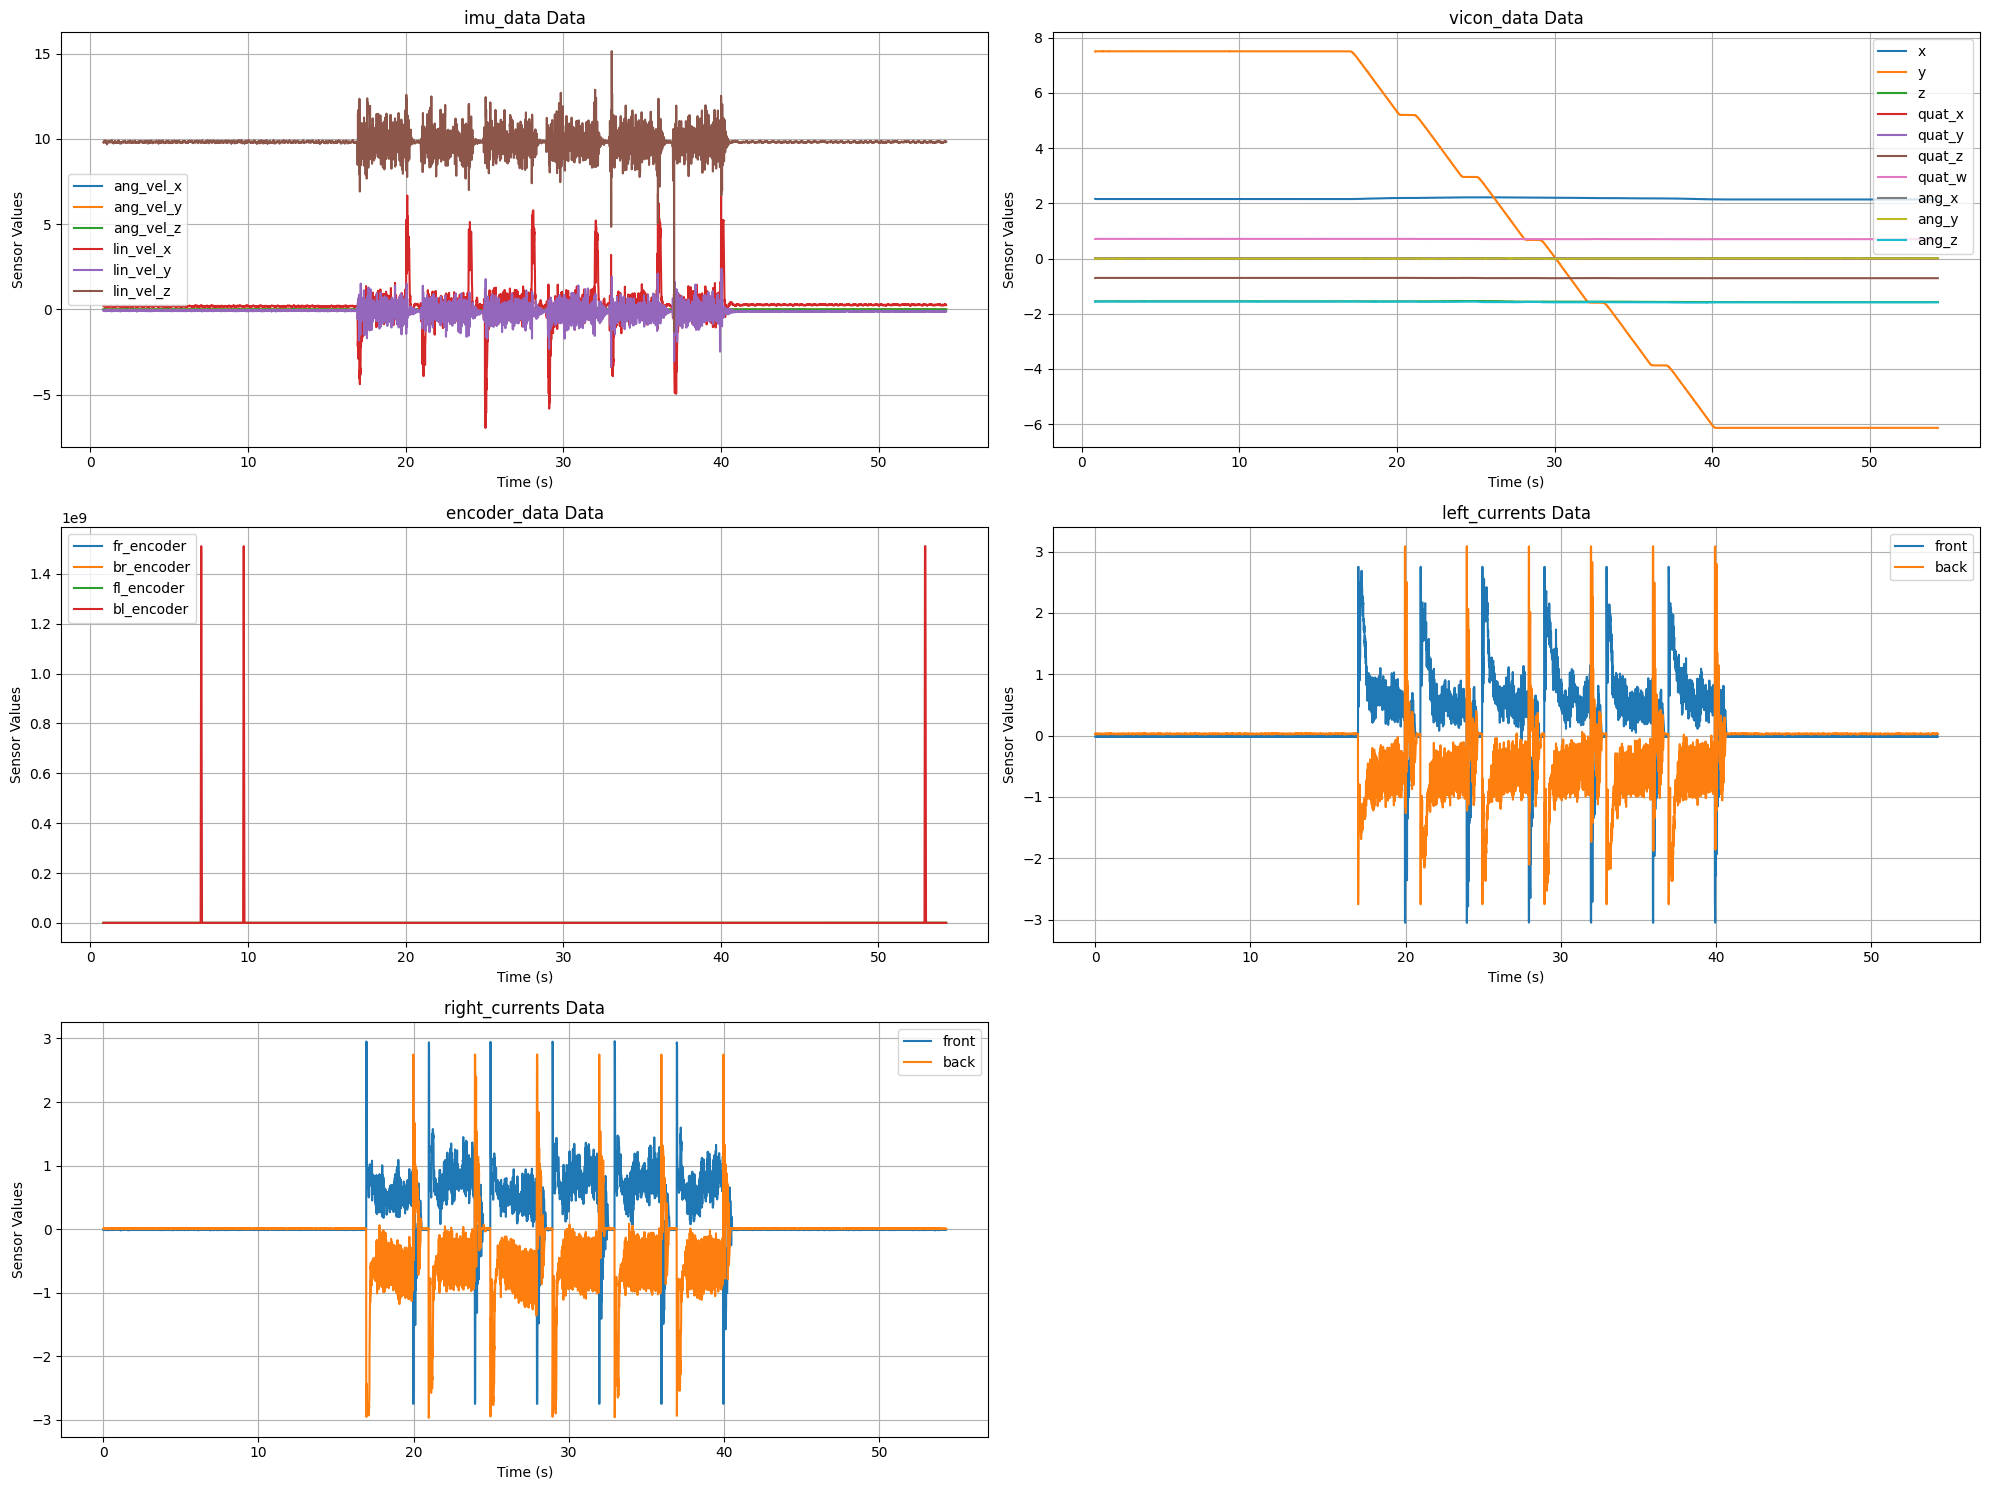

In [1102]:
def plot_bag_data(bag_data):
    """Plot each data object in the given BagData instance using a 3x2 subplot layout."""

    rows, cols = 3, 2  # 3x2 layout
    fig, axes = plt.subplots(rows, cols, figsize=(20, 15))
    axes = axes.flatten()  # Flatten for easy indexing

    for i, (sensor_name, sensor_obj) in enumerate(bag_data):  # Iterate directly
        ax = axes[i]

        ax.set_title(f"{sensor_name} Data")
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Sensor Values")

        # Use the new plotting method to retrieve artists
        sensor_obj.get_plot_artists(ax)

        ax.legend()
        ax.grid(True)

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


bag = bags[0]
plot_bag_data(bag)

# Processing Data

## Vicon Pose Data

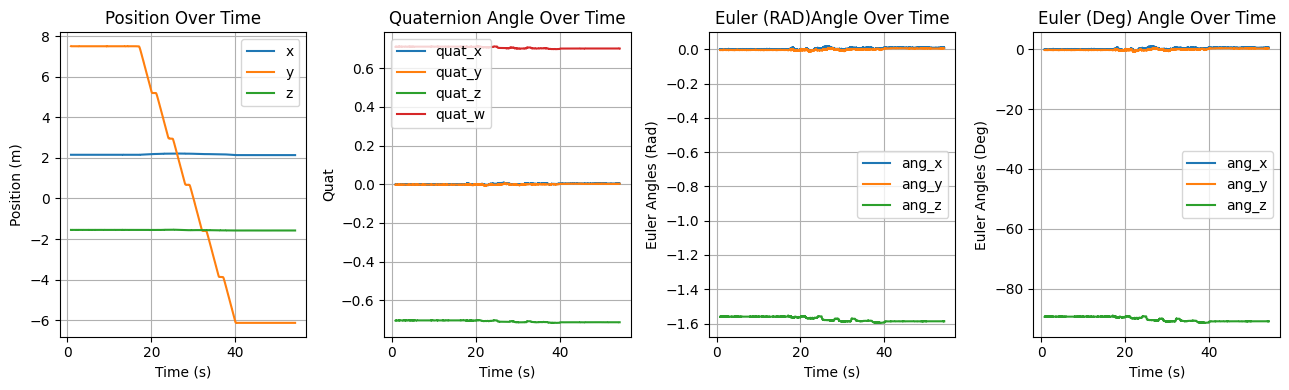

In [1103]:
def plot_vicon(vicon_data: ViconPoseData):
    rows, cols = 1, 4  # 1x3
    fig, axes = plt.subplots(rows, cols, figsize=(13, 4))
    axes = axes.flatten()

    ax = axes[0]
    vicon_data.get_plot_artists(ax, selected_names=["x", "y", "z"])
    ax.set_title("Position Over Time")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Position (m)")
    ax.legend()
    ax.grid(True)

    ax = axes[1]
    vicon_data.get_plot_artists(
        ax, selected_names=["quat_x", "quat_y", "quat_z", "quat_w"]
    )
    ax.set_title("Quaternion Angle Over Time")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Quat")
    ax.legend()
    ax.grid(True)

    ax = axes[2]
    vicon_data.get_plot_artists(ax, selected_names=["ang_x", "ang_y", "ang_z"])
    ax.set_title("Euler (RAD)Angle Over Time")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Euler Angles (Rad)")
    ax.legend()
    ax.grid(True)

    ax = axes[3]
    # vicon_data.get_plot_artists(ax, selected_names=['ang_x','ang_y','ang_z'])
    for i, name in enumerate(["ang_x", "ang_y", "ang_z"]):
        ax.plot(vicon_data.stamp, getattr(vicon_data, name) * (180 / pi), label=name)
        ax.set_title("Euler (Deg) Angle Over Time")
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Euler Angles (Deg)")
    ax.legend()
    ax.grid(True)

    plt.tight_layout()
    plt.show()


vicon_data = bags[0].vicon_data
plot_vicon(vicon_data)

In [1104]:
# Peek at the data.
vicon_data = bags[
    0
].vicon_data  # A reference since vicon_data.data is a mutable type (NDArray)
print(vicon_data.stamp[0:20])

print(f"{vicon_data.data.shape=}")
diff_time = np.diff(vicon_data.stamp[0:40])
print(diff_time)

print(np.var(diff_time))

[0.85324357 0.85330495 0.85333027 0.8632332  0.86328202 0.87323489
 0.87329244 0.88323835 0.88331076 0.89324625 0.90325512 0.90333762
 0.90337413 0.91326026 0.91333708 0.92323434 0.93327626 0.93337078
 0.94326363 0.9433602 ]
vicon_data.data.shape=(10, 10681)
[6.1376000e-05 2.5326000e-05 9.9029300e-03 4.8811000e-05 9.9528800e-03
 5.7542000e-05 9.9459130e-03 7.2413000e-05 9.9354910e-03 1.0008868e-02
 8.2496000e-05 3.6515000e-05 9.8861310e-03 7.6815000e-05 9.8972620e-03
 1.0041918e-02 9.4517000e-05 9.8928490e-03 9.6576000e-05 3.9262000e-05
 9.8927820e-03 9.9906730e-03 1.0890500e-04 2.8555000e-05 9.8406900e-03
 9.4050000e-05 9.9211080e-03 1.1221300e-04 9.8675380e-03 7.7057000e-05
 9.9186180e-03 1.0008411e-02 1.0884000e-04 4.0820000e-05 9.8437700e-03
 7.2437000e-05 9.9252350e-03 7.8403000e-05 9.9254540e-03]
2.4268987696222612e-05


### Removing Outliers
TODO, is there any preprocessing necessary to clean up the vicon data? Should we do a low pass filter here?

## Wheel Data
### Remove encoder count outliers
There are occasional spikes in the odometry data we can pretty easily eliminate by setting a delta threshold.

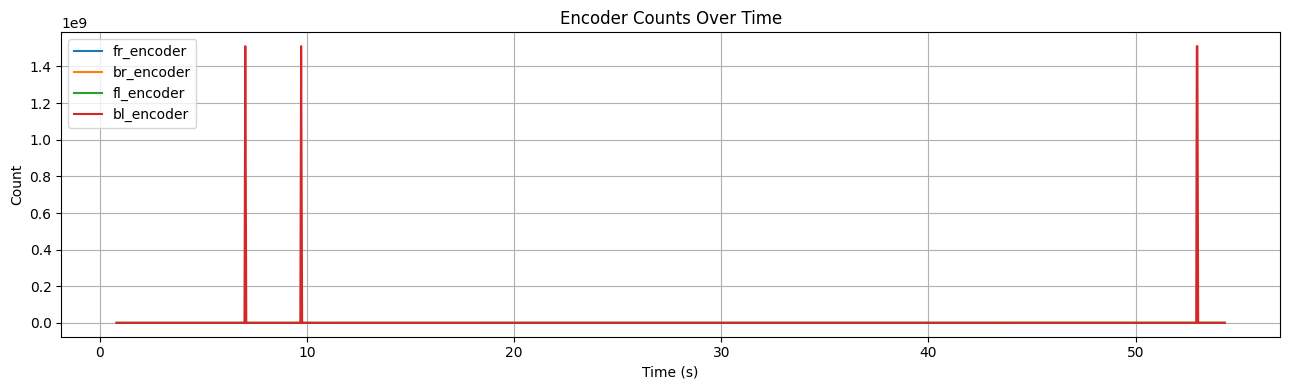

In [1105]:
def plot_encoder(encoder_data: EncoderData):
    fig, ax = plt.subplots(figsize=(13, 4))

    encoder_data.get_plot_artists(
        ax, selected_names=["fr_encoder", "br_encoder", "fl_encoder", "bl_encoder"]
    )
    ax.set_title("Encoder Counts Over Time")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Count")
    ax.legend()
    ax.grid(True)

    plt.tight_layout()
    plt.show()


bag = bags[0]
encoder_data = bag.encoder_data
plot_encoder(encoder_data)

Original number of mesurements (4, 1376)
Cleaned number of mesurements (4, 1366)


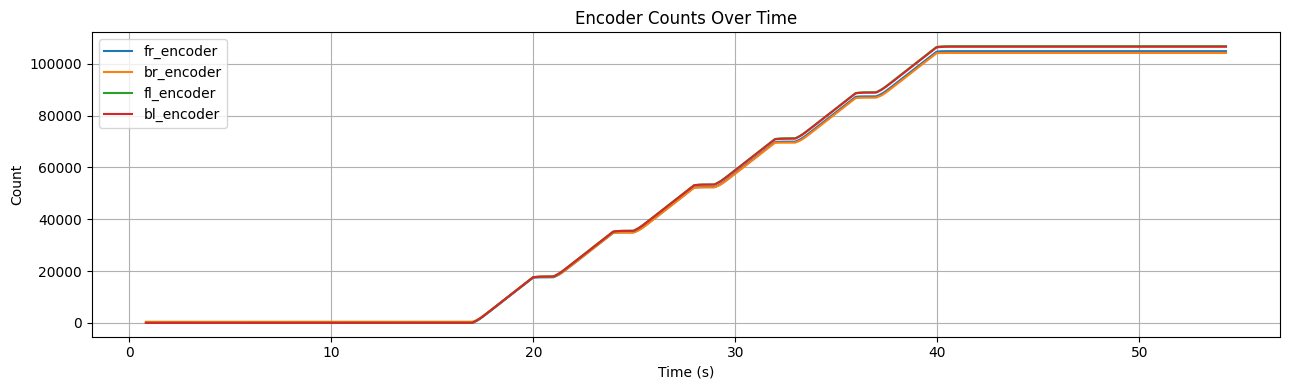

In [1106]:
def remove_encoder_outliers(encoder_data: EncoderData, threshold=1000) -> EncoderData:
    """
    Removes outliers from encoder data based on sudden jumps in encoder counts.

    Parameters:
        encoder_data (NDArray): (5, N) array where:
                                   - Row 0 is time
                                   - Rows 1-4 are encoder counts
        threshold (int): Difference threshold for detecting outliers.

    Returns:
        NDArray: Filtered encoder data with outliers removed.
    """
    assert encoder_data.data.shape[0] == 4, "Expected encoder_data to have 4 rows.."

    # Compute absolute differences between consecutive values
    # Diff gives us n-1 shape.
    diffs = np.abs(np.diff(encoder_data, axis=1))

    # Check the right side difference and the left side differences.
    # This gives us n-1
    outlier_mask = (diffs[:, :-1] > threshold) | (diffs[:, 1:] > threshold)

    # Extend mask to include the first and last columns properly
    first_col = np.zeros((4, 1), dtype=bool)
    last_col = np.zeros((4, 1), dtype=bool)

    first_col[:, 0] = outlier_mask[
        :, 0
    ]  # Extend first column based on first valid outlier
    last_col[:, 0] = outlier_mask[
        :, -1
    ]  # Extend last column based on last valid outlier

    # Concatenate the extended mask
    outlier_mask = np.column_stack(
        [first_col, outlier_mask, last_col]
    )  # Now Shape: (4, N)

    # Create a valid mask by ensuring all encoders are within threshold
    valid_mask = ~np.any(outlier_mask, axis=0)

    # TODO make this prettier.
    encoder_data_cleaned = EncoderData(count=4)
    encoder_data_cleaned.data = np.copy(encoder_data.data[:, valid_mask])
    encoder_data_cleaned.stamp = np.copy(encoder_data.stamp[valid_mask])
    encoder_data_cleaned.count = encoder_data.count
    encoder_data_cleaned.stamp_nsec = np.copy(encoder_data.stamp_nsec[valid_mask])

    encoder_data_cleaned.count = encoder_data_cleaned.data.shape[
        1
    ]  # Update coured.data = np.copy(encoder_data.data[:, valid_mask])

    return encoder_data_cleaned


bag = bags[0]

encoder_data = bag.encoder_data
print("Original number of mesurements", encoder_data.data.shape)
encoder_data_cleaned = remove_encoder_outliers(encoder_data)
print("Cleaned number of mesurements", encoder_data_cleaned.data.shape)

# Add to our BagData
bag.encoder_data_cleaned = encoder_data_cleaned
plot_encoder(encoder_data_cleaned)


## Motor Currents


### Plot MotorCurrentsData

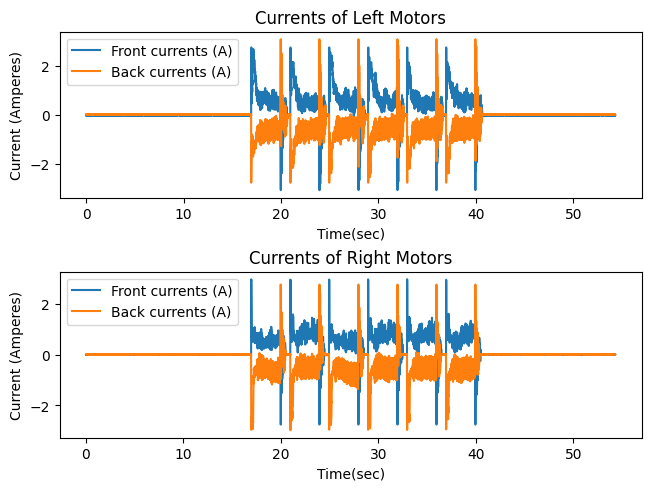

In [1107]:
def plot_currents(currents: list[MotorCurrentsData], titles: list[str] = []):

    num_currents = len(currents)
    
    if num_currents == 1:
        fig, ax = plt.subplots(1, constrained_layout=True)  # Single subplot
        ax = [ax]  # Wrap in a list to standardize iteration
    else:
        fig, ax = plt.subplots(num_currents, constrained_layout=True)  # Multiple subplots


    # fig, ax = plt.subplots(len(currents), constrained_layout=True)


    for i, current in enumerate(currents):
        if titles != []:
            ax[i].set_title(titles[i])
        else:
            ax[i].set_title(current.data_desc)

        ax[i].plot(current.stamp, current.front, label="Front currents (A)")
        ax[i].plot(current.stamp, current.back, label="Back currents (A)")
        ax[i].set_xlabel("Time(sec)")
        ax[i].set_ylabel("Current (Amperes)")
        ax[i].legend()
    plt.show()


bag = bags[0]
currents = [bag.left_currents, bag.right_currents]
plot_currents(currents, titles=["Currents of Left Motors", "Currents of Right Motors"])

## TEMPORARY: Flip back motor currents
These are wired in reverse on robot.

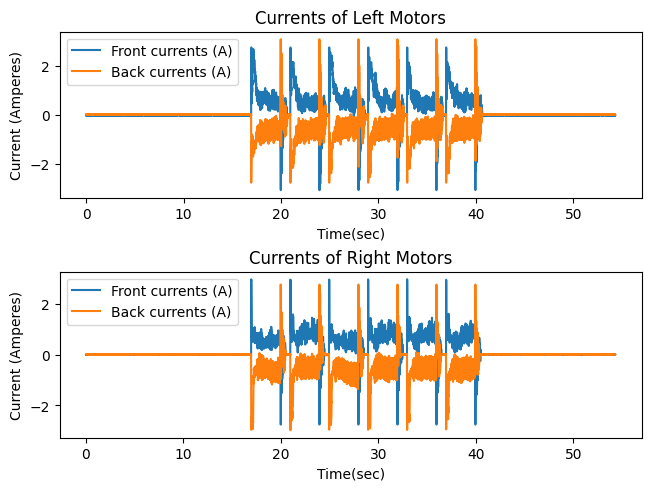

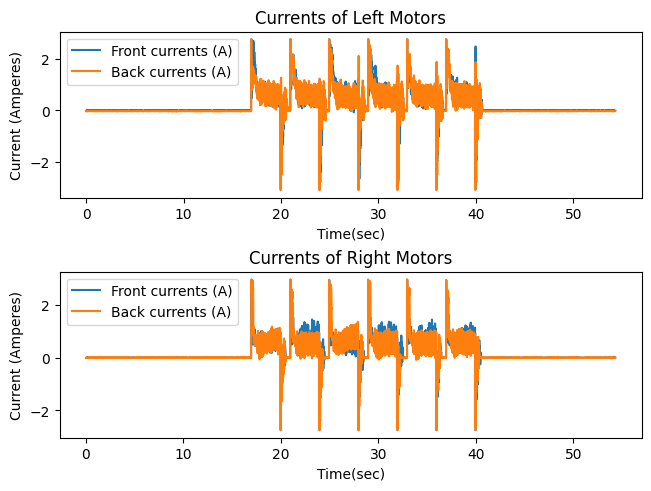

In [1108]:
from copy import deepcopy


def flip_currents(
    currents: MotorCurrentsData, channels: list[str]
) -> MotorCurrentsData:
    """Flip signs on one or both channels of current data. Currently we're flipping the back,
    :param currents: A MotorCurrentsData object with our currents.
    :param channels: A list of with either/both "front" or "back".capitalize

    :return flipped_currents: New MotorCurrentsData object identical to input except for sign flip.
    """
    flipped_currents = deepcopy(currents)
    for channel in channels:
        if channel == "front":  # TODO Fix to have attr setter/getters for DataObjectss
            flipped_currents.data[0, :] = currents.data[0, :] * -1
        if channel == "back":
            flipped_currents.data[1, :] = currents.data[1, :] * -1
    return flipped_currents


bag = bags[0]
left_currents = bag.left_currents
right_currents = bag.right_currents

flipped_left_currents = flip_currents(currents=left_currents, channels=["back"])
flipped_right_currents = flip_currents(currents=right_currents, channels=["back"])

bag.flipped_left_currents = flipped_left_currents
bag.flipped_right_currents = flipped_right_currents

# Test it out
plot_currents(
    currents=[left_currents, right_currents],
    titles=["Currents of Left Motors", "Currents of Right Motors"],
)
plot_currents(
    currents=[flipped_left_currents, flipped_right_currents],
    titles=["Currents of Left Motors", "Currents of Right Motors"],
)


# Creating Derived Data


## Vicon

### Numerical Derivatives For Small dt Data

In [1109]:
from scipy.signal import savgol_filter


def savgol_derivative(data: NDArray, time: NDArray, window_size=21, poly_order=3):
    """
    Compute the numerical derivative using Savitzky-Golay filtering.

    Parameters:
        data (NDArray): (D, N) position or quaternion data.
        time (NDArray): (N,) time vector.
        window_size (int): Filter window size (must be odd).
        poly_order (int): Polynomial order (should be < window_size).

    Returns:
        NDArray: (D, N) filtered derivative (velocity or angular velocity).
    """
    # TODO See how much using a single mean dt value affects accuracy.
    # TODO Would it be better to interp to an evenly spaced dt grid?
    dt = np.mean(
        np.diff(time), axis=0
    )  # Average timestep to avoid noise from small dt variations

    return savgol_filter(
        data, window_length=window_size, polyorder=poly_order, deriv=1, delta=dt, axis=1
    )


def quaternion_derivative_savgol(
    quats: NDArray, time: NDArray, window_size=21, poly_order=3
) -> NDArray:
    """
    Compute the angular velocity from a sequence of quaternions using Savitzky-Golay filtering.

    Parameters:
        quats (NDArray): (4, N) array of quaternions (qx, qy, qz, qw) at each time step.
        time (NDArray): (N,) array of time values corresponding to each quaternion.
        window_size (int): The window length for Savitzky-Golay filtering (must be odd).
        poly_order (int): Polynomial order for Savitzky-Golay filtering.

    Returns:
        NDArray: (3, N) array of angular velocities (wx, wy, wz) in rad/s.
        NDArray: (7, N) array of angular velocities (qx,qy,qz,qw, wx, wy, wz) in rad/s.
    """
    quats = quats.T  # Convert from (4, N) to (N, 4) for scipy.
    print(quats.shape)
    rotations = R.from_quat(quats)

    # Convert quaternion differences to rotation vectors
    rotvecs = np.zeros((len(time), 3))  # (N, 3)
    rotvecs[1:] = (rotations[:-1].inv() * rotations[1:]).as_rotvec()

    # TODO make this not a single scalar constant?
    dt = np.mean(np.diff(time), axis=0)

    # TODO Find optimal way to tune polyorder and window size params to avoid over smoothing/fitting.
    ang_vels = savgol_filter(
        rotvecs.T,
        window_length=window_size,
        polyorder=poly_order,
        deriv=1,
        delta=dt,
        axis=1,
    )

    # Turn euler back to quat?
    quat_vels = R.from_euler("xyz", ang_vels.T).as_quat()
    print("Qual vels", quat_vels.shape)

    ang_vels = np.vstack([ang_vels, quat_vels.T])
    print("Final angles shape", ang_vels.shape)

    return ang_vels  # (7, N)


### Vicon Derived Body Velocity

(10681, 4)
Qual vels (10681, 4)
Final angles shape (7, 10681)
vicon_vels_data.shape=(10, 10681)


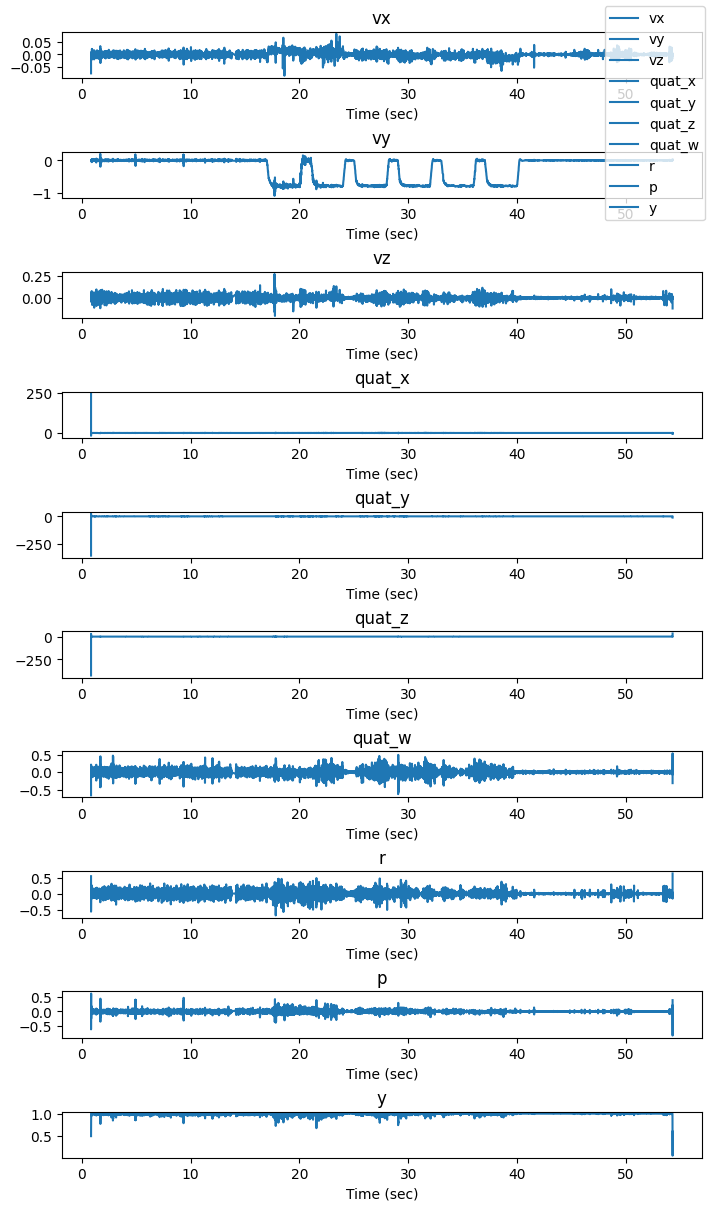

In [1110]:
def plot_vicon_vels(vicon_data: ViconVelsData, title: str = ""):
    fig, ax = plt.subplots(
        len(vicon_data.names), constrained_layout=True, figsize=(7, 12), dpi=100
    )
    data = vicon_data.data
    stamp = vicon_data.stamp

    # Plot using channel names.
    for i, name in enumerate(vicon_data.names):
        ax[i].plot(stamp, data[i, :], label=name)
        ax[i].set_title(name)
        ax[i].set_xlabel("Time (sec)")
    fig.legend()
    plt.show()


bag = bags[0]

vicon_data = bag.vicon_data  # x,y,z,qx,qy,qz,qw,r,p,y.

# Compute linaer velocity using 2nd order differences


# Compute linear velocity using savgol.
lin_vels = savgol_derivative(
    vicon_data.data[:3, :], vicon_data.stamp, window_size=17, poly_order=9
)

# Compute angular vel using savgol.
ang_vels = quaternion_derivative_savgol(
    vicon_data.data[3:7, :], vicon_data.stamp, window_size=17, poly_order=16
)

# Stack and plot
vicon_vels_data = np.vstack([lin_vels, ang_vels])
print(f"{vicon_vels_data.shape=}")

vicon_vels = ViconVelsData(vicon_data.count)
vicon_vels.data = vicon_vels_data
vicon_vels.stamp = vicon_data.stamp

bag.vicon_vels = vicon_vels
plot_vicon_vels(vicon_vels, "Vicon Vels")


## Encoders

### Get Wheel Angles From Encoder Counts

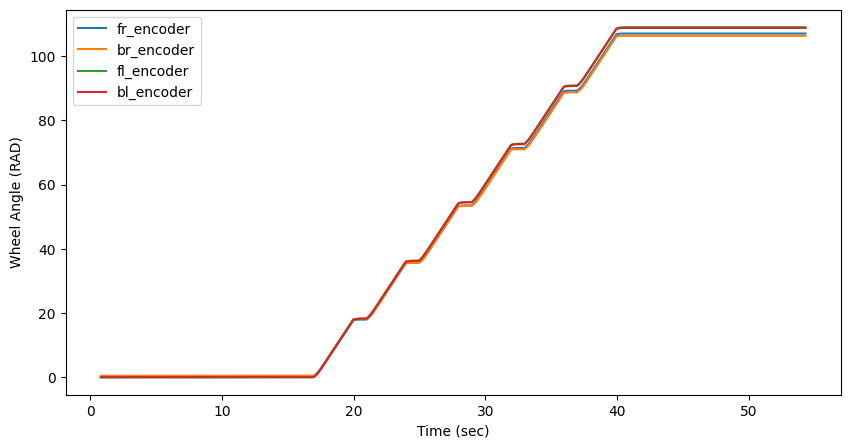

In [1111]:
def plot_wheel_angs(angle_data: WheelAnglesData):
    data = angle_data.data
    stamp = angle_data.stamp

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.set_ylabel("Wheel Angle (RAD)")
    ax.set_xlabel("Time (sec)")
    for i, name in enumerate(wheel_angles.names):
        ax.plot(stamp, data[i], label=name)
    ax.legend()


# Calculate wheel angles from encoders counts.
def encoder_to_rad(encoder_data: EncoderData, ppr=1539, radius=0.33) -> WheelAnglesData:
    data = encoder_data.data

    # TODO Do we get counts or pulses?
    cpr = ppr * 4
    # Compute wheel angles in RAD. (4,N)
    # wheel_rad = np.vstack([encoder_data[0], (encoder_data[1:] / cpr) * (2 * np.pi)])
    angle_rads = (data / cpr) * (2 * np.pi)

    # # Wheel angles in DEG.
    # wheel_deg["wheel_angle_deg"] = (encoder_data["encoder_count"] / CPR) * 360.0

    # Return new EncoderData object.
    angle_data = WheelAnglesData(encoder_data.count)
    angle_data.stamp = encoder_data.stamp
    angle_data.names = encoder_data.names
    angle_data.data = angle_rads

    return angle_data


bag = bags[0]
encoder_data = bag.encoder_data
# encoder_data = np.vstack([encoder_data.stamp, encoder_data.data])
encoder_data = remove_encoder_outliers(encoder_data)
wheel_angles = encoder_to_rad(encoder_data)


bag.wheel_angles = wheel_angles

plot_wheel_angs(wheel_angles)

### Angle Velocities

vel_data.shape=(4, 1366)


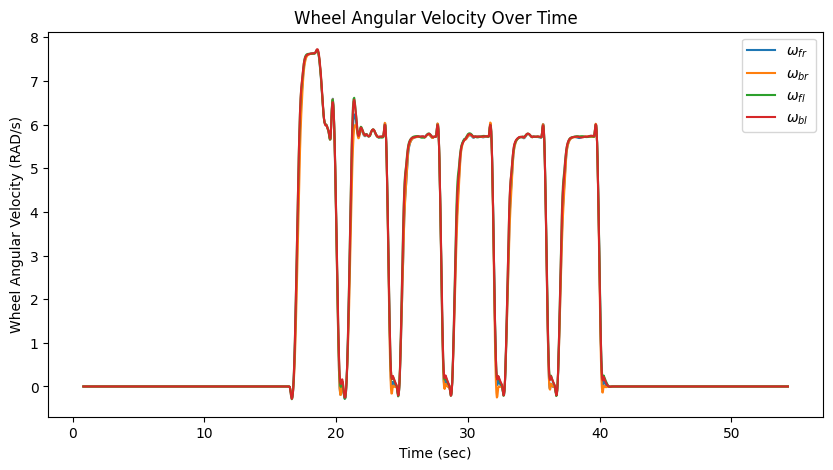

In [1112]:
# Find wheel angular velocities in RAD/s


def plot_wheel_vels(vel_data: WheelVelsData):
    data = vel_data.data
    stamp = vel_data.stamp

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.set_ylabel("Wheel Angular Velocity (RAD/s)")
    ax.set_xlabel("Time (sec)")
    ax.set_title("Wheel Angular Velocity Over Time")
    for i, name in enumerate(vel_data.names):
        ax.plot(stamp, data[i], label=name)
    ax.legend()


def calc_wheel_vels(angles_data: WheelAnglesData) -> WheelVelsData:
    data = angles_data.data
    stamp = angles_data.stamp

    # Find numerical deriv
    vel_data = savgol_derivative(data, angles_data.stamp)
    print(f"{vel_data.shape=}")

    wheel_vels = WheelVelsData(angles_data.count)
    wheel_vels.stamp = stamp
    wheel_vels.data = vel_data
    return wheel_vels


bag = bags[0]
wheel_angles = bag.wheel_angles

wheel_vels = calc_wheel_vels(wheel_angles)
bag.wheel_vels = wheel_vels

plot_wheel_vels(wheel_vels)

# Time Sync Data
Let's make things simple and have all data we fit our models on here be time syncrhonized. Up/Downdsample and interpolate
all other data to the odometry data.


## Better Linear Interp Downsampling to Wheel Odometry Frequency

target_data.data.shape=(4, 1366)
target_data.stamp.shape=(1366,)
datum.shape=(10, 10681), time_vec.shape=(10681,)
interp_data_result.shape=(10, 1366)


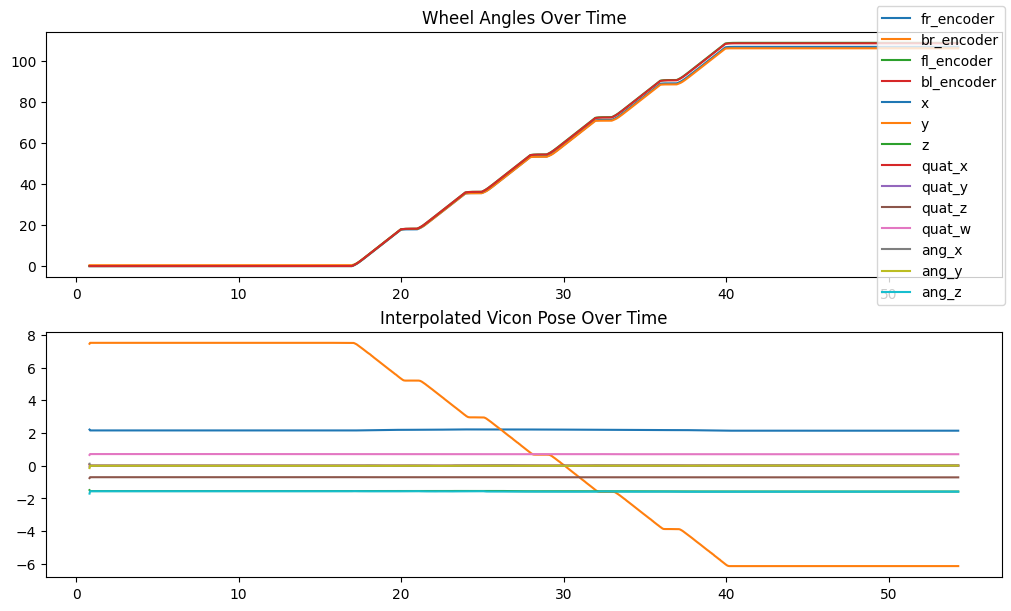

In [1113]:
def interp_to_wheels(
    datas: list[GenericData], target_data: WheelAnglesData
) -> list[GenericData]:
    """Use a linear interpolation to sync all the data to the joint_state data.  Return these as a list?
    Or maybe a dict?

    Parameters:
        data (NDArray): (K,N) array of floats where K=0 is time and K=1: are variables and N is time step

    Returns:
    """

    interp_funcs = []  # Don't really need this...
    interp_datas: list[GenericData] = []
    print(f"{target_data.data.shape=}")
    print(f"{target_data.stamp.shape=}")

    # For each source of data (that's not wheel data)
    for data in datas:
        interp_data = deepcopy(data)
        interp_data.stamp = target_data.stamp  # Will have same time vec.

        time_vec = data.stamp  # original time vec.
        datum = data.data  # Original data.
        print(f"{datum.shape=}, {time_vec.shape=}")

        interp_func = interp1d(
            time_vec, datum, kind="linear", fill_value="extrapolate", axis=1
        )
        interp_funcs.append(interp_func)

        interp_data_result = interp_func(target_data.stamp)
        print(f"{interp_data_result.shape=}")

        interp_data.data = interp_data_result
        interp_datas.append(interp_data)

    return interp_datas


bag = bags[0]
encoder_data = bag.encoder_data
vicon_data = bag.vicon_data

# encoder_data = np.vstack([encoder_data.stamp, encoder_data.data])
# vicon_data = np.vstack([vicon_data.stamp, vicon_data.data])


# Remove outliers from encoders.
encoder_data = remove_encoder_outliers(encoder_data, threshold=20_000)

# Get wheel angles.
wheel_angles = encoder_to_rad(encoder_data)


interp_data = interp_to_wheels([vicon_data], wheel_angles)

# Plot the data now and see how they align.
fig, ax = plt.subplots(2, 1, constrained_layout=True, figsize=(10, 6))
ax[0].set_title("Wheel Angles Over Time")
ax[0].plot(wheel_angles.stamp, wheel_angles.data.T, label=wheel_angles.names)

vicon_interp = interp_data[0]
ax[1].set_title("Interpolated Vicon Pose Over Time")
ax[1].plot(vicon_interp.stamp, vicon_interp.data.T, label=vicon_interp.names)

# plot_wheel_angs()
# ax.plot(wheel_angles.stamp, wheel_angles.data[0])
fig.legend()


# Slip
This is a simple way to make observations related to the frictional characterstics of the system. If we can relate the longitudinal friction forces to the percentage of slip we can estimate the tire's longutidinal stiffness parameter which is roughly linearlyly correlated with the COF. This is supported by Pacejka's Magic Formula (MF). We only use part of that model here. The MF model/formula is highly emprirical and many of the tire parameters require fancy equipment or desctructive testing to find. But perhaps we can use charts/tables to use more of the model?

## Longitudinal Slip Ratio Formula
There are two forms of the slip ratio formula. They are respectively better suited to acceleration(sliding) or deceleration (skidding) mode driving.

For the acceleration/sliding mode where $v < r \omega$ we normalize w.r.t $r \omega$. The result is that the range of $s$ is $s \in [-1, 0]$:

$$
s = \frac{r \omega - v}{r \omega}
$$



For the deceleration/skidding mode where $v > r \omega$ we normalize w.r.t $v$. The result is that the range of $s$ is $s \in [-1, 0]$:


$$
s = \frac{r \omega - v}{v}
$$



We can make a piecewise continuous formula for the slip ratio by using the $max()$ function:
$$
s = \frac{r \omega - v}{max(r \omega, v)}
$$

At near zero velocities this is makes for very unstable slip estimates. Applying a minimum threshold seems to work.
## Slip-Slope
This method comes from 


## Lateral Slip
To find lateral as well as longitudinal slip we will need to transform the inertial frame body velocity to give the inertial frame wheel velocities. This is relatively straightforward since we a TF transform saved in our rosbag. We can apply this before converting to numpy data arrays.

We can them find the lateral slip 

#  Model Based Friction Estimation
This kind of friction estimation requires us to now have a model of either the tire and or the vehicle. This is where we can mix and match models and parts of models together. Some might be kinematic like the 

# Differential Drive Kinematic Model.
Let's try running the data we have through a basic differential drive model. We can compare the error of this to the the true data.
This will let us establish the general pattern for creating a "runner" function which reports a loss. Then we can extend to 
models whose parameters we must fit. We don't *need* to do this iteratively but
let's do it anyway.

<img src="Images/Differential_Drive_Kinematics_of_a_Wheeled_Mobile_Robot.png" width=400/>
# TODO cite wikipedia for image.


## Iterative DiffDrive

In [1114]:
from diff_drive_utils import DiffDriveState

state: DiffDriveState = DiffDriveState(np.zeros((3, 100)))


In [1115]:
from typing import Any, ParamSpecArgs, TypedDict


class DiffDriveParams(TypedDict):
    r: float
    b: float


class WheelSpeeds(TypedDict):
    omega_l: float
    omega_r: float


x = DiffDriveParams(r=2, b=4)


r, b = (x[k] for k in ("r", "b"))


print(r, b)
for name, val in x.items():
    print(name, val)
    # Make local objects programmatically

2 4
r 2
b 4


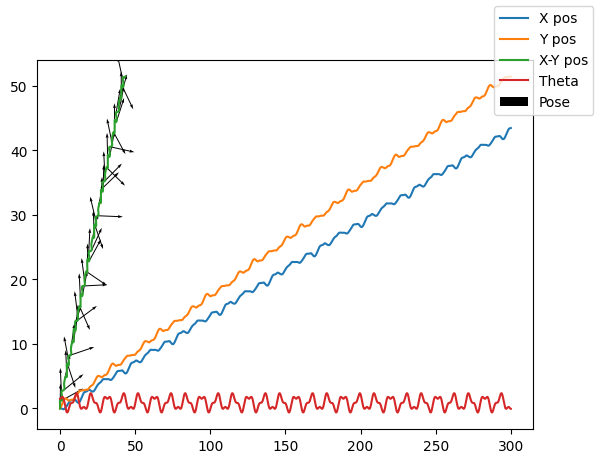

In [1116]:
# Make a function for a differential drive model
from typing import Any


def diff_drive(
    time: float,
    state: NDArray[np.float64],
    omega_l: float,
    omega_r: float,
    r: float,
    b: float,
) -> NDArray:
    """foo!

    :param state: X, Y, Theta
    :param time: Current time
    :param omega_l: _description_
    :param omega_r: _description_
    :param r: _description_
    :param b: _description_
    :return: _description_
    """
    x, y, theta = state

    # CALCULATED INTERMEDIATES:
    v_l = r * omega_l
    v_r = r * omega_r

    # Calc body frame velocities.
    Vx = (v_l + v_r) / 2
    theta_prime = (v_r - v_l) / b

    # Transform to world frame.
    x_prime = Vx * math.cos(theta)
    y_prime = Vx * math.sin(theta)

    # Return state_prime
    return np.array([x_prime, y_prime, theta_prime])


# Make our time vector.
t_start, t_end, dt = 0, 300, 0.001
steps: int = int((t_end - t_start) / dt)
t_vec = np.linspace(t_start, t_end, steps)

# Set up params and initial state.
state: DiffDriveState = DiffDriveState(state=np.zeros((3, len(t_vec))))
state[:, 0] = [0, 0, 1.5]  # (X,Y,Theta)


# Offset wheel angle vels.
phase_shift = np.array([0.6, 1.4]).reshape(-1, 1)


# Make control input/measurements of wheel angular vels
# shift_wheel_time = phase_shift.reshape(1,-1) *
wheel_vels = 1 + np.sin(phase_shift * np.tile(t_vec.reshape(1, -1), (2, 1)))


diff_drive_params = dict(r=0.33, b=0.5)

# Do euler integration.
for idx, t in enumerate(t_vec[:-1]):
    omega_l, omega_r = wheel_vels[:, idx]
    state_prime = diff_drive(
        state=state[:, idx],
        time=t,
        omega_l=omega_l,
        omega_r=omega_r,
        **diff_drive_params,
    )
    state[:, idx + 1] = state[:, idx] + dt * state_prime

# Loop through rosbag data and run our model.
# Calculate new state using our model output.


def plot_diff_model(state, t_vec):
    fig, ax = plt.subplots()
    ax.plot(t_vec, state[0, :], label="X pos")
    ax.plot(t_vec, state[1, :], label="Y pos")
    ax.plot(state[0, :], state[1, :], label="X-Y pos")
    # ax.plot(t_vec, obs[0,:], label="Omega_L")
    ax.plot(t_vec, state[2, :], label="Theta")

    hop = int(steps / 50)
    ax.quiver(
        state[0, ::hop],
        state[1, ::hop],
        np.cos(state[2, ::hop]),
        np.sin(state[2, ::hop]),
        angles="xy",
        scale=20,
        label="Pose",
        width=0.002,
    )
    fig.legend()
    plt.show()


plot_diff_model(state, t_vec)

In [1117]:
# # Try with solve_ivp
# # Need to make our function continuous time? So can't use just raw data...
# # t_eval is just a vector for computed outputs. fun needs to be continuously callable which real
# # data is obviously not going to be. Can we use interpolation here safely? How would we know if we are
# # inappropriately smoothing our data?

# # Make our time vector.
# t_start, t_end, dt = 0, 300, 0.01
# steps:int = int((t_end - t_start) / dt)
# t_vec = np.linspace(t_start, t_end, steps)



# # Set up params and initial state.
# state: DiffDriveState = DiffDriveState(state=np.zeros((3, len(t_vec))))
# state[:, 0] = [0, 0, 1.5]  # (X,Y,Theta)


# # Offset wheel angle vels.
# phase_shift = np.array([.6, 1.4]).reshape(-1, 1)


# # Make control input/measurements of wheel angular vels
# # shift_wheel_time = phase_shift.reshape(1,-1) *
# wheel_vels = 1 + np.sin(phase_shift * np.tile(t_vec.reshape(1, -1), (2, 1)))

# diff_drive_params = dict(r=0.33, b=0.5)

# state = DiffDriveState(np.zeros((3, len(t_vec))))
# state[:, 0] = [0, 0, 1.5]  # Set x0.


# observations = {
#     "omega_l": wheel_vels[0],
#     "omega_r": wheel_vels[1],
# }
# model_args={
#     "r": 0.33,
#     "b": 0.5
# }

# def run_model(t,y):
#     return diff_drive(t,y,**args)

# soln = solve_ivp(
#     fun=lambda t, y: run_model(t, y), 
#     y0=state[:, 0], t_eval=t_vec, t_span=(t_start, t_end)
# )
# print(soln)


Start pos (3,)


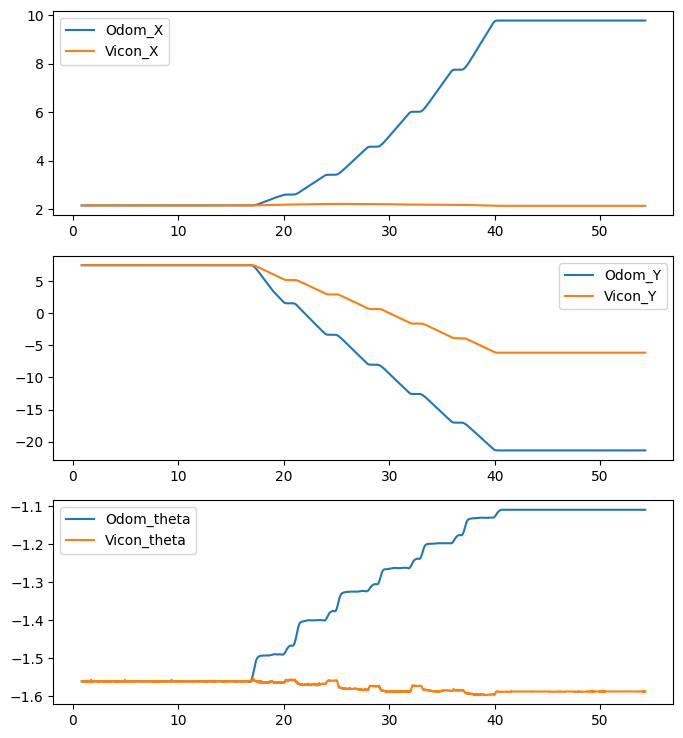

In [1118]:
# Try over real data.
bag = bags[0]

# Get start pose and ground truth.
"""How best to get our start pose and ground truth poses? We have our vicon data here but that's in the vicon frame? So 
let's either transform and have all our numpy data in one frame. Or we could do the transform here but that kind of sucks.

We could just compare by pretending the robot started at wherever it was in the vicon frame. This should be valid.
"""
vicon_data = bag.vicon_data # Data is xyz qx qy qz r p y
vicon_pos = np.vstack([vicon_data.x, vicon_data.y, vicon_data.ang_z])
start_pos = vicon_pos[:,0]
print("Start pos", start_pos.shape)


all_wheel_vels = bag.wheel_vels
t_vec = all_wheel_vels.stamp
steps = len(t_vec)

l_wheel_vels = np.mean(all_wheel_vels.data[0:2, :], axis=0) # Assume wheels on a side are of the same vels.
r_wheel_vels = np.mean(all_wheel_vels.data[2:4, :], axis=0)

wheel_vels = np.vstack([l_wheel_vels, r_wheel_vels])



# Set up params and initial state.
state: DiffDriveState = DiffDriveState(state=np.zeros((3, len(t_vec))))
# state[:, 0] = [0, 0, 0]  # (X,Y,Theta)
state[:, 0] = start_pos

diff_drive_params = dict(r=0.29, b=1.56)

# Do euler integration.
for idx, t in enumerate(t_vec[:-1]):
    dt = t_vec[idx + 1] - t_vec[idx]
    omega_l, omega_r = wheel_vels[:, idx]
    state_prime = diff_drive(
        state=state[:, idx],
        time=t,
        omega_l=omega_l,
        omega_r=omega_r,
        **diff_drive_params,
    )
    state[:, idx + 1] = state[:, idx] + dt * state_prime

# plot_diff_model(state, t_vec)

# plot_diff_model(vicon_pos, vicon_data.stamp)




# Compare the true pose and odom pose.
fig, ax = plt.subplots(3,1, figsize=(8,9))
row = 0
ax[row].plot(t_vec, state[row],label="Odom_X")
ax[row].plot(vicon_data.stamp, vicon_pos[row,:] ,label="Vicon_X")
ax[row].legend()

row = 1
ax[row].plot(t_vec, state[row],label="Odom_Y")
ax[row].plot(vicon_data.stamp, vicon_pos[row,:] ,label="Vicon_Y")
ax[row].legend()

row = 2
ax[row].plot(t_vec, state[row],label="Odom_theta")
ax[row].plot(vicon_data.stamp, vicon_pos[row,:] ,label="Vicon_theta")
ax[row].legend()


In [1119]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.interpolate import interp1d

# # Extract time vector
# t_vec = all_wheel_vels.stamp
# # Extract wheel velocities
# l_wheel_vels = np.mean(all_wheel_vels.data[0:2, :], axis=0)  # Left wheels avg
# r_wheel_vels = np.mean(all_wheel_vels.data[2:4, :], axis=0)  # Right wheels avg

# # Compute body velocities using the diff_drive model.
# body_vels = np.array([
#     diff_drive(
#         time=t_vec[idx],
#         state=state[:, idx],
#         omega_l=l_wheel_vels[idx],
#         omega_r=r_wheel_vels[idx],
#         **diff_drive_params
#     ) for idx in range(len(t_vec))
# ]).T  # Transpose to shape (3, steps)

# Vx_odom = body_vels[0, :]
# Vy_odom = body_vels[1, :]
# omega_odom = body_vels[2, :]

# vicon_vels = bag.vicon_vels
# Vx_vicon = vicon_vels.x
# Vy_vicon = vicon_vels.y
# omega_vicon = vicon_vels.ang_z

# skip = 0
# end_skip = 1


# # Make time sync'd data.
# interp_Vx_vicon = interp1d(vicon_data.stamp, Vx_vicon, kind="linear", fill_value="extrapolate")
# interp_Vy_vicon = interp1d(vicon_data.stamp, Vy_vicon, kind="linear", fill_value="extrapolate")
# interp_omega_vicon = interp1d(vicon_data.stamp, omega_vicon, kind="linear", fill_value="extrapolate")

# Vx_vicon_resampled = interp_Vx_vicon(t_vec)
# Vy_vicon_resampled = interp_Vy_vicon(t_vec)
# omega_vicon_resampled = interp_omega_vicon(t_vec)


# # Remove vels below a threshold before calculating slip otherwise numerica isntability blows the estimate up when standing still.
# vel_threshold = 0.05
# ang_threshold = 0.01
# # Mask where any velocity is too low
# valid_mask = (np.abs(Vx_odom) > vel_threshold) | \
#              (np.abs(Vy_odom) > vel_threshold) | \
#              (np.abs(omega_odom) > ang_threshold)


# # Pos slip -> Sliding
# # Neg slip -> Skidding
# slip_x = np.where(valid_mask, (Vx_odom - Vx_vicon_resampled) / np.maximum(Vx_odom, Vx_vicon_resampled), np.nan)
# slip_y = np.where(valid_mask, (Vy_odom - Vy_vicon_resampled) / np.maximum(Vy_odom, Vy_vicon_resampled), np.nan)
# slip_theta = np.where(valid_mask, (omega_odom - omega_vicon_resampled) / np.maximum(omega_odom, omega_vicon_resampled), np.nan)


# clip = 20
# slip_x = np.clip(slip_x, -clip, clip)[skip:-end_skip]
# slip_y = np.clip(slip_y, -clip, clip)[skip:-end_skip]
# slip_theta = np.clip(slip_theta, -clip, clip)[skip:-end_skip]

# t_vec = t_vec[skip:-end_skip]

# # Plot slip over time
# fig, ax = plt.subplots(3, 1, figsize=(7, 8), dpi=100, constrained_layout=True)

# # Longitudinal Slip
# ax1 = ax[0]
# ax1.set_title("Whole Body Velocity Slip. Lock wheels and skid to stop test.\n Pos slip->sliding, Neg slip->skidding")
# ax1.plot(t_vec, slip_x, label="Longitudinal Slip (%)", color="red")
# ax1.plot(t_vec, Vx_vicon_resampled[skip:-end_skip], label="Vicon Velocity X", color="orange", linestyle="--")
# ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
# ax1.set_ylabel("Slip X (%)")
# ax1.legend()

# # Second y-axis for velocity
# ax2 = ax1.twinx()
# ax2.set_ylim(-1, 1)  # Set the limits for the second y-axis
# ax2.set_ylabel("Velocity (m/s)", color="orange")
# ax2.tick_params(axis="y", labelcolor="orange")

# # Lateral Slip
# ax1 = ax[1]
# ax1.plot(t_vec, slip_y, label="Lateral Slip (%)", color="blue")
# ax1.plot(t_vec, Vy_vicon_resampled[skip:-end_skip], label="Vicon Velocity Y", color="cyan", linestyle="--")
# ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
# ax1.set_ylabel("Slip Y (%)")
# ax1.legend()

# # Second y-axis for velocity
# ax2 = ax1.twinx()
# ax2.set_ylim(-1, 1)  # Set the limits for the second y-axis
# ax2.set_ylabel("Velocity (m/s)", color="cyan")
# ax2.tick_params(axis="y", labelcolor="cyan")

# # Angular Slip
# ax1 = ax[2]
# ax1.plot(t_vec, slip_theta, label="Angular Slip (%)", color="green")
# ax1.plot(t_vec, omega_vicon_resampled[skip:-end_skip], label="Vicon Angular Velocity", color="lime", linestyle="--")
# ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
# ax1.set_ylabel("Slip Theta (%)")
# ax1.legend()

# # Second y-axis for velocity
# ax2 = ax1.twinx()
# ax2.set_ylim(-1, 1)  # Set the limits for the second y-axis
# ax2.set_ylabel("Angular Velocity (rad/s)", color="lime")
# ax2.tick_params(axis="y", labelcolor="lime")

# plt.xlabel("Time (s)")
# plt.show()


# Estimating $\mu$.
We find the normalized friction force $\mu$ as,

$$
\mu = \frac{F_{fr}}{F_N}
$$

We can treat $F_fr$ as the force caused by our motors (longitudinal case). 

$$
F_{fr} = r \tau
$$
Where $r$ is the tire radius and $\tau$ is the motor torque which is $\tau = kI$ where k is a constant torque-current param of the motor and $I$ is the current in Amperes. So we get,
$$
\mu = \frac{kI}{F_N}
$$

If we assume $F_N$ to be constant and $k$ as well we simply say,

$$\mu = I$$

which works if we're comparing short term measurements.

(8228,)
Left Average Current: [-0.02013122 -0.0191336  -0.01617988 ... -0.01807653 -0.01696956
 -0.01959638], avg_currents.data.shape=(2, 8228)
Right Average Current: [-0.00900361 -0.00668058 -0.00828968 ... -0.01105291 -0.00867809
 -0.0057743 ]


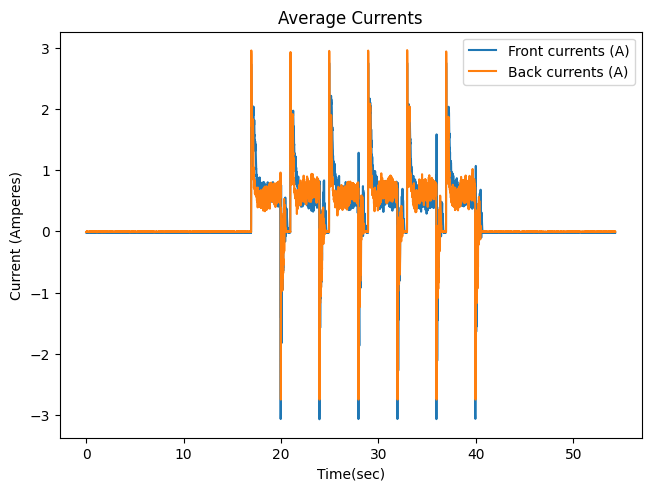

In [1120]:
bag = bags[0]



left_currents = bag.flipped_left_currents
right_currents = bag.flipped_right_currents

avg_currents = MotorCurrentsData(right_currents.count)
avg_currents.stamp = right_currents.stamp

# Interp and sync up currents to right side.
interp_left_currents = interp1d(left_currents.stamp, left_currents.data, kind="linear", fill_value="extrapolate")
resampled_left_currents = interp_left_currents(right_currents.stamp)


# Calculate the average left and right currents
left_avg = np.mean(resampled_left_currents.data, axis=0)  # Average over all front and back left currents
right_avg = np.mean(right_currents.data, axis=0)  # Average over all front and back right currents

print(left_avg.shape)


# Assign the averages to the new motor currents object
avg_currents.data[0] = left_avg  # Store the left average in the 'front' property
avg_currents.data[1] = right_avg  # Store the right average in the 'back' property

# Now you have the averaged data in motor_currents, and you can access it as needed
print(f"Left Average Current: {avg_currents.front}, {avg_currents.data.shape=}")
print(f"Right Average Current: {avg_currents.back}")


plot_currents([avg_currents],["Average Currents"])

In [1121]:
"""Now find force over slip. Plot this as a cloud. We should see a linear trend to the points. Do this only for longitudinal slip slip_x. 
The ratio force/slip is k, the longitudinal stiffness which roughly correlates to the max friction.
"""

# Interp to this.
# t_vec = all_wheel_vels.stamp

# # avg_currents

# # slip_x

# all_current_avg = np.mean(avg_currents.data, axis=0)
# print(all_current_avg.shape)

# all_current_avg_interp = interp1d(avg_currents.stamp, avg_currents.data, kind="linear", fill_value="extrapolate")
# all_current_avg_resampled = all_current_avg_interp(t_vec)

# k = all_current_avg_resampled / slip_x



'Now find force over slip. Plot this as a cloud. We should see a linear trend to the points. Do this only for longitudinal slip slip_x. \nThe ratio force/slip is k, the longitudinal stiffness which roughly correlates to the max friction.\n'

# Things


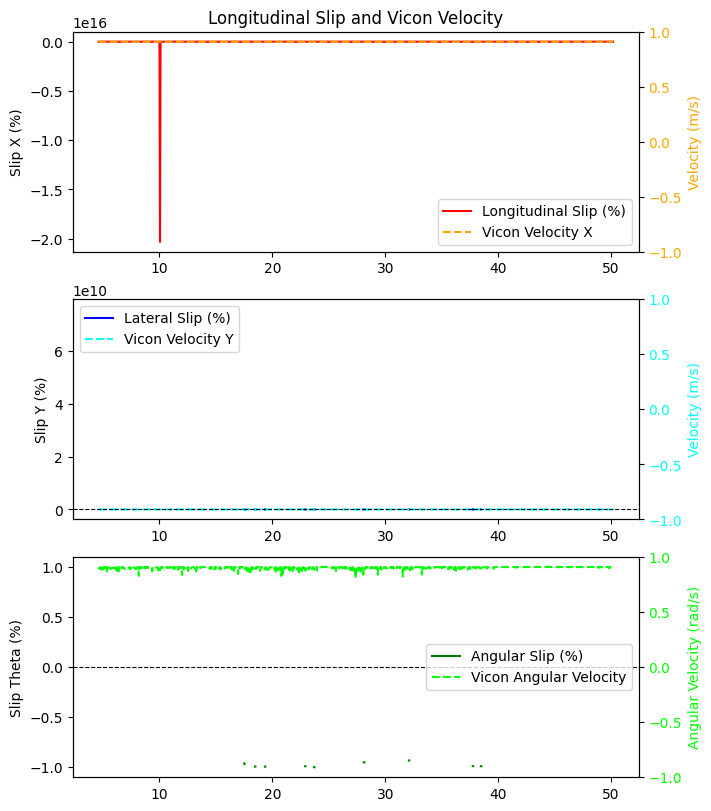

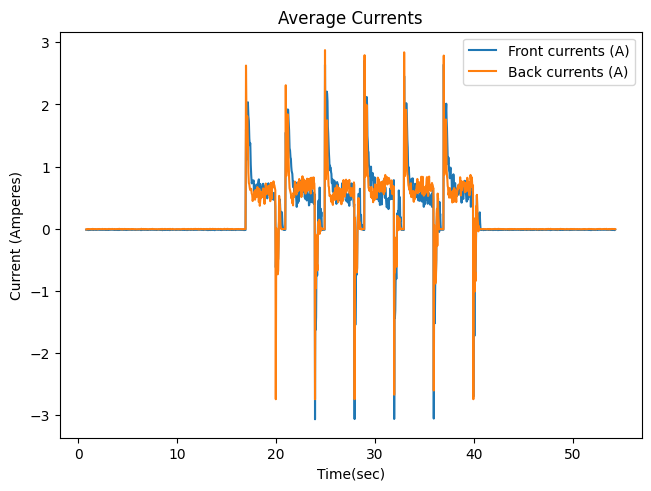

In [1122]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d


def calculate_body_odometry(t_vec, l_wheel_vels, r_wheel_vels, state, diff_drive_params):
    """ Compute body velocities using the diff_drive model. """
    body_vels = np.array([
        diff_drive(
            time=t_vec[idx],
            state=state[:, idx],
            omega_l=l_wheel_vels[idx],
            omega_r=r_wheel_vels[idx],
            **diff_drive_params
        ) for idx in range(len(t_vec))
    ]).T  # Transpose to shape (3, steps)
    
    Vx_odom = body_vels[0, :]
    Vy_odom = body_vels[1, :]
    omega_odom = body_vels[2, :]
    
    return Vx_odom, Vy_odom, omega_odom

# 1. Function for Data Interpolation
def interpolate_data(time_vector, vicon_data, data_field):
    """ Interpolates Vicon velocity data to the given time vector. """
    interp_func = interp1d(vicon_data.stamp, getattr(vicon_data, data_field), kind="linear", fill_value="extrapolate")
    return interp_func(time_vector)

# 2. Function for Slip Calculation
def calculate_slip(odom_data, vicon_data_resampled, valid_mask):
    """ Calculate slip for longitudinal, lateral, and angular velocities. """

    # slip_x = np.where(valid_mask, (Vx_odom - Vx_vicon_resampled) / np.maximum(Vx_odom, Vx_vicon_resampled), np.nan)
    slip_x = np.where(valid_mask, (odom_data[0] - vicon_data_resampled[0]) / np.maximum(odom_data[0], vicon_data_resampled[0]), 0)

    slip_y = np.where(valid_mask, (odom_data[1] - vicon_data_resampled[1]) / np.maximum(odom_data[1], vicon_data_resampled[1]), np.nan)
    slip_theta = np.where(valid_mask, (odom_data[2] - vicon_data_resampled[2]) / np.maximum(odom_data[2], vicon_data_resampled[2]), np.nan)
    
    # slip_x = np.where(valid_mask, (vicon_data_resampled[0] - odom_data[0]) / np.maximum(odom_data[0], vicon_data_resampled[0]), np.nan)
    # slip_y = np.where(valid_mask, (vicon_data_resampled[1] - odom_data[1]) / np.maximum(odom_data[1], vicon_data_resampled[1]), np.nan)
    # slip_theta = np.where(valid_mask, (vicon_data_resampled[2] - odom_data[2]) / np.maximum(odom_data[2], vicon_data_resampled[2]), np.nan)
    return slip_x, slip_y, slip_theta

# 3. Function for Current Averaging
def average_motor_currents(left_currents, right_currents, time_vector):
    """ Resample the left currents and compute the averages of left and right currents. """
    interp_left_currents = interp1d(left_currents.stamp, left_currents.data, kind="linear", fill_value="extrapolate")
    interp_right_currents = interp1d(right_currents.stamp, right_currents.data, kind="linear", fill_value="extrapolate")

    resampled_left_currents = interp_left_currents(time_vector)
    resampled_right_currents = interp_right_currents(time_vector)

    left_avg = np.mean(resampled_left_currents, axis=0)
    right_avg = np.mean(resampled_right_currents, axis=0)
    return left_avg, right_avg

def plot_data(t_vec, slip_x, slip_y, slip_theta, vicon_data_resampled, avg_currents, start=None, stop=None):
    """ Plot slip over time and average motor currents with optional range selection. """
    
    # Apply slicing if start and stop indices are provided
    if start is not None and stop is not None:
        t_vec = t_vec[start:-stop]
        slip_x = slip_x[start:-stop]
        slip_y = slip_y[start:-stop]
        slip_theta = slip_theta[start:-stop]
        vicon_data_resampled = [v[start:-stop] for v in vicon_data_resampled]

    fig, ax = plt.subplots(3, 1, figsize=(7, 8), dpi=100, constrained_layout=True)

    # Longitudinal Slip
    ax1 = ax[0]
    ax1.set_title("Longitudinal Slip and Vicon Velocity")
    ax1.plot(t_vec, slip_x, label="Longitudinal Slip (%)", color="red")
    ax1.plot(t_vec, vicon_data_resampled[0], label="Vicon Velocity X", color="orange", linestyle="--")
    # ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax1.set_ylabel("Slip X (%)")
    ax1.legend()

    # Second y-axis for velocity
    ax2 = ax1.twinx()
    ax2.set_ylim(-1, 1)  # Set the limits for the second y-axis
    ax2.set_ylabel("Velocity (m/s)", color="orange")
    ax2.tick_params(axis="y", labelcolor="orange")

    # Lateral Slip
    ax1 = ax[1]
    ax1.plot(t_vec, slip_y, label="Lateral Slip (%)", color="blue")
    ax1.plot(t_vec, vicon_data_resampled[1], label="Vicon Velocity Y", color="cyan", linestyle="--")
    ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax1.set_ylabel("Slip Y (%)")
    ax1.legend()

    # Second y-axis for velocity
    ax2 = ax1.twinx()
    ax2.set_ylim(-1, 1)  # Set the limits for the second y-axis
    ax2.set_ylabel("Velocity (m/s)", color="cyan")
    ax2.tick_params(axis="y", labelcolor="cyan")

    # Angular Slip
    ax1 = ax[2]
    ax1.plot(t_vec, slip_theta, label="Angular Slip (%)", color="green")
    ax1.plot(t_vec, vicon_data_resampled[2], label="Vicon Angular Velocity", color="lime", linestyle="--")
    ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax1.set_ylabel("Slip Theta (%)")
    ax1.legend()

    # Second y-axis for velocity
    ax2 = ax1.twinx()
    ax2.set_ylim(-1, 1)  # Set the limits for the second y-axis
    ax2.set_ylabel("Angular Velocity (rad/s)", color="lime")
    ax2.tick_params(axis="y", labelcolor="lime")

    plt.xlabel("Time (s)")
    plt.show()

    # Plot average currents
    plot_currents([avg_currents], ["Average Currents"])

def get_avg_wheel_vels(wheel_vels:WheelVelsData):
    """Average wheels on each side L/R."""
    l_wheel_vels = np.mean(wheel_vels.data[0:2, :], axis=0) # Assume wheels on a side are of the same vels.
    r_wheel_vels = np.mean(wheel_vels.data[2:4, :], axis=0)
    wheel_vels = np.vstack([l_wheel_vels, r_wheel_vels])

    return wheel_vels



bag = bags[0]
vicon_pos = bag.vicon_data
vicon_pos_data = np.vstack([vicon_pos.x, vicon_pos.y, vicon_pos.ang_z])

start_pos = vicon_pos_data[:,0]
state[:, 0] = start_pos # For odom calc.





# Collect vicon velocity data from bag.
vicon_vels = bag.vicon_vels

Vx_vicon = vicon_vels.x
Vy_vicon = vicon_vels.y
omega_vicon = vicon_vels.ang_z

vicon_vel_stack = np.vstack([Vx_vicon, Vy_vicon, omega_vicon])



all_wheel_vels = bag.wheel_vels
t_vec = all_wheel_vels.stamp # Interp to this.
steps = len(t_vec)

left_currents = bag.flipped_left_currents
right_currents = bag.flipped_right_currents


# Get L/R averaged wheel angular vels.
wheel_vels_avg = get_avg_wheel_vels(all_wheel_vels)
l_wheel_vels = wheel_vels_avg[0]
r_wheel_vels = wheel_vels_avg[1]

# Get body odom.
body_vels = calculate_body_odometry(t_vec, l_wheel_vels, r_wheel_vels, state, diff_drive_params)


# Step 1: Interpolate velocities
Vx_vicon_resampled = interpolate_data(t_vec, vicon_vels, "x")
Vy_vicon_resampled = interpolate_data(t_vec, vicon_vels, "y")
omega_vicon_resampled = interpolate_data(t_vec, vicon_vels, "ang_z")


vel_threshold = 0.02
valid_mask = (np.abs(Vx_vicon_resampled) > vel_threshold)

# # Step 2: Slip Calculation
slip_x, slip_y, slip_theta = calculate_slip(body_vels, [Vx_vicon_resampled, Vy_vicon_resampled, omega_vicon_resampled], valid_mask)

# # Step 3: Current Averaging
left_avg, right_avg = average_motor_currents(left_currents, right_currents, t_vec)


# # Create avg_currents object
avg_currents = MotorCurrentsData(len(right_avg))  # Assuming same length for left and right
avg_currents.stamp = t_vec
avg_currents.data[0] = left_avg
avg_currents.data[1] = right_avg


# # Step 4: Plotting
plot_data(t_vec, slip_x, slip_y, slip_theta, [Vx_vicon_resampled, Vy_vicon_resampled, omega_vicon_resampled], avg_currents,
start=100,stop=100)



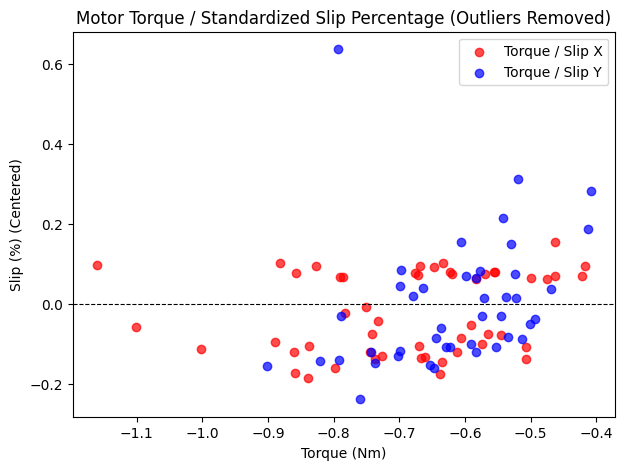

In [1123]:
def remove_outliers(data, threshold=3.5):
    """Remove outliers using the Median Absolute Deviation (MAD) method."""
    median = np.nanmedian(data)
    mad = np.nanmedian(np.abs(data - median))
    modified_z_score = 0.6745 * (data - median) / (mad + 1e-6)  # Prevent div by zero
    return np.where(np.abs(modified_z_score) < threshold, data, np.nan)

def standardize_slip(slip_data):
    """Standardize slip values by subtracting the mean to remove offset."""
    mean_slip = np.nanmean(slip_data)
    return slip_data - mean_slip

def plot_torque_vs_slip_filtered(t_vec, slip_x, slip_y, slip_theta, avg_currents, start=None, stop=None):
    """ Plot motor torques divided by slip percentage as a scatter plot, with outliers removed and slip centered at zero. """

    # Apply slicing if start and stop indices are provided
    if start is not None and stop is not None:
        t_vec = t_vec[start:-stop]
        slip_x = slip_x[start:-stop]
        slip_y = slip_y[start:-stop]
        slip_theta = slip_theta[start:-stop]
        avg_currents_data = np.copy(avg_currents.data[:, start:-stop])
    else:
        avg_currents_data = np.copy(avg_currents.data)
    # Compute torques (assuming motor torque is proportional to motor current)
    motor_torque = avg_currents_data  # Replace with actual torque computation if needed

    motor_torque *= -1

    # Avoid division by zero
    slip_x_safe = np.where(np.abs(slip_x) > 1e-6, slip_x, np.nan)
    slip_y_safe = np.where(np.abs(slip_y) > 1e-6, slip_y, np.nan)

    torque_x = motor_torque[0] / slip_x_safe
    torque_y = motor_torque[1] / slip_y_safe

    # Remove outliers
    torque_x_filtered = remove_outliers(torque_x)
    torque_y_filtered = remove_outliers(torque_y)
    slip_x_filtered = remove_outliers(slip_x_safe)
    slip_y_filtered = remove_outliers(slip_y_safe)

    # Standardize slip values to remove offset
    slip_x_standardized = standardize_slip(slip_x_filtered)
    slip_y_standardized = standardize_slip(slip_y_filtered)

    # Scatter plot
    fig, ax = plt.subplots(figsize=(7, 5), dpi=100)
    ax.scatter(torque_x_filtered, slip_x_standardized, label="Torque / Slip X", color="red", alpha=0.7)
    ax.scatter(torque_y_filtered, slip_y_standardized, label="Torque / Slip Y", color="blue", alpha=0.7)
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)

    ax.set_xlabel("Torque (Nm)")
    ax.set_ylabel("Slip (%) (Centered)")
    ax.set_title("Motor Torque / Standardized Slip Percentage (Outliers Removed)")
    ax.legend()
    plt.show()



plot_torque_vs_slip_filtered(t_vec, slip_x, slip_y, slip_theta, avg_currents, start=100, stop=100)

Longitudinal Stiffness (Slope): 0.331871 Nm/% Slip


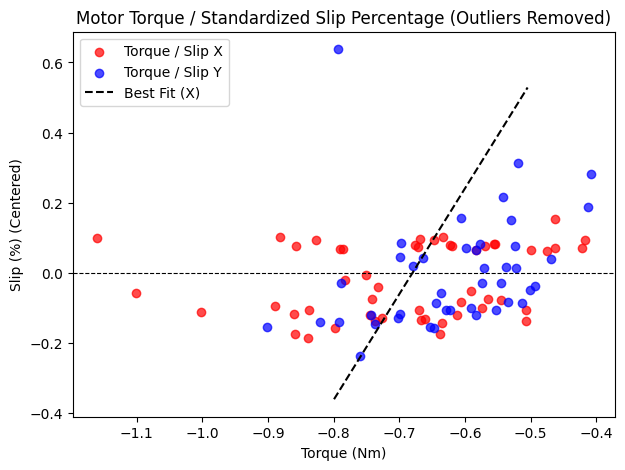

In [1124]:

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress


def remove_outliers(data, threshold=3.5):
    """Remove outliers using the Median Absolute Deviation (MAD) method."""
    median = np.nanmedian(data)
    mad = np.nanmedian(np.abs(data - median))
    modified_z_score = 0.6745 * (data - median) / (mad + 1e-6)  # Prevent div by zero
    return np.where(np.abs(modified_z_score) < threshold, data, np.nan)

def standardize_slip(slip_data):
    """Standardize slip values by subtracting the mean to remove offset."""
    mean_slip = np.nanmean(slip_data)
    return slip_data - mean_slip

def plot_torque_vs_slip_filtered(t_vec, slip_x, slip_y, slip_theta, avg_currents, start=None, stop=None):
    """Plot motor torques divided by slip percentage as a scatter plot, fit a line, and compute longitudinal stiffness."""

    # Apply slicing if start and stop indices are provided
    if start is not None and stop is not None:
        t_vec = t_vec[start:-stop]
        slip_x = slip_x[start:-stop]
        slip_y = slip_y[start:-stop]
        slip_theta = slip_theta[start:-stop]
        avg_currents_data = np.copy(avg_currents.data[:, start:-stop])
    else:
        avg_currents_data = np.copy(avg_currents.data)

    # Compute torques (assuming motor torque is proportional to motor current)
    motor_torque = avg_currents_data * -1  # Negate torques as per previous behavior

    # Avoid division by zero
    slip_x_safe = np.where(np.abs(slip_x) > 1e-6, slip_x, np.nan)
    slip_y_safe = np.where(np.abs(slip_y) > 1e-6, slip_y, np.nan)

    torque_x = motor_torque[0] / slip_x_safe
    torque_y = motor_torque[1] / slip_y_safe

    # Remove outliers
    torque_x_filtered = remove_outliers(torque_x)
    torque_y_filtered = remove_outliers(torque_y)
    slip_x_filtered = remove_outliers(slip_x_safe)
    slip_y_filtered = remove_outliers(slip_y_safe)

    # Standardize slip values to remove offset
    slip_x_standardized = standardize_slip(slip_x_filtered)
    slip_y_standardized = standardize_slip(slip_y_filtered)

    # Remove NaNs before fitting regression
    valid_mask = ~np.isnan(slip_x_standardized) & ~np.isnan(torque_x_filtered)
    slip_x_valid = slip_x_standardized[valid_mask]
    torque_x_valid = torque_x_filtered[valid_mask]

    # Compute linear regression (line of best fit)
    slope, intercept, r_value, p_value, std_err = linregress(slip_x_valid, torque_x_valid)
    print(f"Longitudinal Stiffness (Slope): {slope:.6f} Nm/% Slip")

    # Generate regression line points
    slip_x_fit = np.linspace(np.nanmin(slip_x_standardized), np.nanmax(slip_x_standardized), 100)
    torque_x_fit = slope * slip_x_fit + intercept

    # Scatter plot with best-fit line
    fig, ax = plt.subplots(figsize=(7, 5), dpi=100)
    ax.scatter(torque_x_filtered, slip_x_standardized, label="Torque / Slip X", color="red", alpha=0.7)
    ax.scatter(torque_y_filtered, slip_y_standardized, label="Torque / Slip Y", color="blue", alpha=0.7)
    ax.plot(torque_x_fit, slip_x_fit, color="black", linestyle="--", label="Best Fit (X)")

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Torque (Nm)")
    ax.set_ylabel("Slip (%) (Centered)")
    ax.set_title("Motor Torque / Standardized Slip Percentage (Outliers Removed)")
    ax.legend()
    plt.show()
plot_torque_vs_slip_filtered(t_vec, slip_x, slip_y, slip_theta, avg_currents, start=100, stop=100)

In [1125]:
# # Plot slip over time
# fig, ax = plt.subplots(3, 1, figsize=(7, 8), dpi=100, constrained_layout=True)

# # Longitudinal Slip
# ax1 = ax[0]
# ax1.set_title("Whole Body Velocity Slip. Lock wheels and skid to stop test.\n Pos slip->sliding, Neg slip->skidding")
# ax1.plot(t_vec, slip_x, label="Longitudinal Slip (%)", color="red")
# ax1.plot(t_vec, Vx_vicon_resampled, label="Vicon Velocity X", color="orange", linestyle="--")
# ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
# ax1.set_ylabel("Slip X (%)")
# ax1.legend()

# # # Second y-axis for velocity
# # ax2 = ax1.twinx()
# # ax2.set_ylim(-1, 1)  # Set the limits for the second y-axis
# # ax2.set_ylabel("Velocity (m/s)", color="orange")
# # ax2.tick_params(axis="y", labelcolor="orange")

# # # Lateral Slip
# # ax1 = ax[1]
# # ax1.plot(t_vec, slip_y, label="Lateral Slip (%)", color="blue")
# # ax1.plot(t_vec, Vy_vicon_resampled, label="Vicon Velocity Y", color="cyan", linestyle="--")
# # ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
# # ax1.set_ylabel("Slip Y (%)")
# # ax1.legend()

# # # Second y-axis for velocity
# # ax2 = ax1.twinx()
# # ax2.set_ylim(-1, 1)  # Set the limits for the second y-axis
# # ax2.set_ylabel("Velocity (m/s)", color="cyan")
# # ax2.tick_params(axis="y", labelcolor="cyan")

# # # Angular Slip
# # ax1 = ax[2]
# # ax1.plot(t_vec, slip_theta, label="Angular Slip (%)", color="green")
# # ax1.plot(t_vec, omega_vicon_resampled, label="Vicon Angular Velocity", color="lime", linestyle="--")
# # ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
# # ax1.set_ylabel("Slip Theta (%)")
# # ax1.legend()

# # # Second y-axis for velocity
# # ax2 = ax1.twinx()
# # ax2.set_ylim(-1, 1)  # Set the limits for the second y-axis
# # ax2.set_ylabel("Angular Velocity (rad/s)", color="lime")
# # ax2.tick_params(axis="y", labelcolor="lime")

# plt.xlabel("Time (s)")
# plt.show()


Longitudinal Stiffness (Slope X): 0.901844 Nm/% Slip


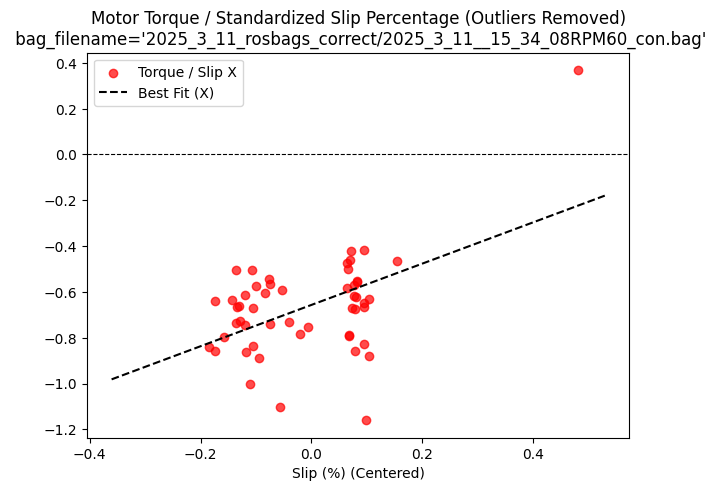

In [1126]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress


def remove_outliers(data, threshold=4.5):
    """Remove outliers using the Median Absolute Deviation (MAD) method."""
    median = np.nanmedian(data)
    mad = np.nanmedian(np.abs(data - median))
    modified_z_score = 0.6745 * (data - median) / (mad + 1e-6)  # Prevent div by zero
    return np.where(np.abs(modified_z_score) < threshold, data, np.nan)


def standardize_slip(slip_data):
    """Standardize slip values by subtracting the mean to remove offset."""
    mean_slip = np.nanmean(slip_data)
    return slip_data - mean_slip


def plot_torque_vs_slip_xy(t_vec, slip_x, slip_y, avg_currents, start=None, stop=None):
    """Plot motor torques divided by slip percentage as a scatter plot, fit separate lines for X and Y, and compute longitudinal stiffness."""

    # Apply slicing if start and stop indices are provided
    if start is not None and stop is not None:
        slip_x = slip_x[start:-stop]
        slip_y = slip_y[start:-stop]
        avg_currents_data = np.copy(avg_currents.data[:, start:-stop])
    else:
        avg_currents_data = np.copy(avg_currents.data)

    # Compute torques (assuming motor torque is proportional to motor current)
    motor_torque = avg_currents_data * -1  # Negate torques as per previous behavior

    # Avoid division by zero
    slip_x_safe = np.where(np.abs(slip_x) > 1e-6, slip_x, np.nan)
    slip_y_safe = np.where(np.abs(slip_y) > 1e-6, slip_y, np.nan)

    torque_x = motor_torque[0] / slip_x_safe
    torque_y = motor_torque[1] / slip_y_safe

    # Remove outliers
    torque_x_filtered = remove_outliers(torque_x)
    torque_y_filtered = remove_outliers(torque_y)
    slip_x_filtered = remove_outliers(slip_x_safe)
    slip_y_filtered = remove_outliers(slip_y_safe)

    # Standardize slip values to remove offset
    slip_x_standardized = standardize_slip(slip_x_filtered)
    slip_y_standardized = standardize_slip(slip_y_filtered)

    # Remove NaNs before fitting regression for X
    valid_mask_x = ~np.isnan(slip_x_standardized) & ~np.isnan(torque_x_filtered)
    slip_x_valid = slip_x_standardized[valid_mask_x]
    torque_x_valid = torque_x_filtered[valid_mask_x]

    # Compute linear regression (line of best fit) for X
    slope_x, intercept_x, _, _, _ = linregress(slip_x_valid, torque_x_valid)
    print(f"Longitudinal Stiffness (Slope X): {slope_x:.6f} Nm/% Slip")

    # Remove NaNs before fitting regression for Y
    valid_mask_y = ~np.isnan(slip_y_standardized) & ~np.isnan(torque_y_filtered)
    slip_y_valid = slip_y_standardized[valid_mask_y]
    torque_y_valid = torque_y_filtered[valid_mask_y]

    # Compute linear regression (line of best fit) for Y
    slope_y, intercept_y, _, _, _ = linregress(slip_y_valid, torque_y_valid)
    # print(f"Lateral Stiffness (Slope Y): {slope_y:.6f} Nm/% Slip")

    # Generate regression line points
    slip_x_fit = np.linspace(np.nanmin(slip_x_standardized), np.nanmax(slip_x_standardized), 100)
    torque_x_fit = slope_x * slip_x_fit + intercept_x

    slip_y_fit = np.linspace(np.nanmin(slip_y_standardized), np.nanmax(slip_y_standardized), 100)
    torque_y_fit = slope_y * slip_y_fit + intercept_y

    # Scatter plot with best-fit lines
    fig, ax = plt.subplots(figsize=(7, 5), dpi=100)
    ax.scatter(slip_x_standardized, torque_x_filtered, label="Torque / Slip X", color="red", alpha=0.7)
    # ax.scatter(slip_y_standardized, torque_y_filtered, label="Torque / Slip Y", color="blue", alpha=0.7)
    ax.plot(slip_x_fit, torque_x_fit, color="black", linestyle="--", label="Best Fit (X)")
    # ax.plot(slip_y_fit, torque_y_fit, color="green", linestyle="--", label="Best Fit (Y)")

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Slip (%) (Centered)")
    # ax.set_ylabel("Torque (Nm)")
    ax.set_title(f"Motor Torque / Standardized Slip Percentage (Outliers Removed)\n {bag_filename=}")
    ax.legend()
    plt.show()


# Example usage:
plot_torque_vs_slip_xy(t_vec, slip_x, slip_y, avg_currents, start=100, stop=100)

# plot_torque_vs_slip_filtered(t_vec, slip_x, slip_y, slip_theta, avg_currents, start=100, stop=100)

Longitudinal Stiffness (Slope X): 0.217399 Nm/% Slip
Plot saved as torque_vs_slip_2025_3_11_rosbags_correct_2025_3_11__15_34_08RPM60_con.bag.png


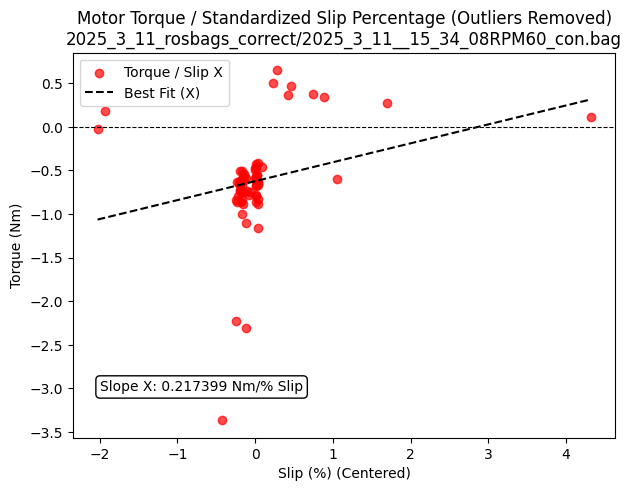

In [1131]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress


def remove_outliers(data, threshold=30.5):
    """Remove outliers using the Median Absolute Deviation (MAD) method."""
    median = np.nanmedian(data)
    mad = np.nanmedian(np.abs(data - median))
    modified_z_score = 0.6745 * (data - median) / (mad + 1e-6)  # Prevent div by zero
    return np.where(np.abs(modified_z_score) < threshold, data, np.nan)


def standardize_slip(slip_data):
    """Standardize slip values by subtracting the mean to remove offset."""
    mean_slip = np.nanmean(slip_data)
    return slip_data - mean_slip


def plot_torque_vs_slip_xy(t_vec, slip_x, slip_y, avg_currents, bag_filename, start=None, stop=None):
    """Plot motor torques divided by slip percentage as a scatter plot, fit separate lines for X and Y, and compute longitudinal stiffness."""

    # Apply slicing if start and stop indices are provided
    if start is not None and stop is not None:
        slip_x = slip_x[start:-stop]
        slip_y = slip_y[start:-stop]
        avg_currents_data = np.copy(avg_currents.data[:, start:-stop])
    else:
        avg_currents_data = np.copy(avg_currents.data)

    # Compute torques (assuming motor torque is proportional to motor current)
    motor_torque = avg_currents_data * -1  # Negate torques as per previous behavior

    # Avoid division by zero
    slip_x_safe = np.where(np.abs(slip_x) > 1e-6, slip_x, np.nan)
    slip_y_safe = np.where(np.abs(slip_y) > 1e-6, slip_y, np.nan)

    torque_x = motor_torque[0] / slip_x_safe
    torque_y = motor_torque[1] / slip_y_safe

    # Remove outliers
    torque_x_filtered = remove_outliers(torque_x)
    torque_y_filtered = remove_outliers(torque_y)
    slip_x_filtered = remove_outliers(slip_x_safe)
    slip_y_filtered = remove_outliers(slip_y_safe)

    # Standardize slip values to remove offset
    slip_x_standardized = standardize_slip(slip_x_filtered)
    slip_y_standardized = standardize_slip(slip_y_filtered)

    # Remove NaNs before fitting regression for X
    valid_mask_x = ~np.isnan(slip_x_standardized) & ~np.isnan(torque_x_filtered)
    slip_x_valid = slip_x_standardized[valid_mask_x]
    torque_x_valid = torque_x_filtered[valid_mask_x]

    # Compute linear regression (line of best fit) for X
    slope_x, intercept_x, _, _, _ = linregress(slip_x_valid, torque_x_valid)
    print(f"Longitudinal Stiffness (Slope X): {slope_x:.6f} Nm/% Slip")

    # Remove NaNs before fitting regression for Y
    valid_mask_y = ~np.isnan(slip_y_standardized) & ~np.isnan(torque_y_filtered)
    slip_y_valid = slip_y_standardized[valid_mask_y]
    torque_y_valid = torque_y_filtered[valid_mask_y]

    # Compute linear regression (line of best fit) for Y
    slope_y, intercept_y, _, _, _ = linregress(slip_y_valid, torque_y_valid)
    # print(f"Lateral Stiffness (Slope Y): {slope_y:.6f} Nm/% Slip")

    # Generate regression line points
    slip_x_fit = np.linspace(np.nanmin(slip_x_standardized), np.nanmax(slip_x_standardized), 100)
    torque_x_fit = slope_x * slip_x_fit + intercept_x

    slip_y_fit = np.linspace(np.nanmin(slip_y_standardized), np.nanmax(slip_y_standardized), 100)
    torque_y_fit = slope_y * slip_y_fit + intercept_y

    # Scatter plot with best-fit lines
    fig, ax = plt.subplots(figsize=(7, 5), dpi=100)
    ax.scatter(slip_x_standardized, torque_x_filtered, label="Torque / Slip X", color="red", alpha=0.7)
    # ax.scatter(slip_y_standardized, torque_y_filtered, label="Torque / Slip Y", color="blue", alpha=0.7)
    ax.plot(slip_x_fit, torque_x_fit, color="black", linestyle="--", label="Best Fit (X)")
    # ax.plot(slip_y_fit, torque_y_fit, color="green", linestyle="--", label="Best Fit (Y)")

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Slip (%) (Centered)")
    ax.set_ylabel("Torque (Nm)")
    ax.set_title(f"Motor Torque / Standardized Slip Percentage (Outliers Removed)\n{bag_filename}")

    ax.legend()

        # Add slope annotation to the plot
    ax.text(0.05, 0.15, f"Slope X: {slope_x:.6f} Nm/% Slip", transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white"))


    # Save the figure with the filename including bag_filename
    safe_filename = bag_filename.replace("/", "_").replace("\\", "_")

    filename = f"torque_vs_slip_{safe_filename}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Plot saved as {filename}")


    # ax.text(0.05, 0.85, f"Slope Y: {slope_y:.6f} Nm/% Slip", transform=ax.transAxes, fontsize=10,
    #     verticalalignment='top', bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white"))


    plt.show()


# Example usage:
plot_torque_vs_slip_xy(t_vec, slip_x, slip_y, avg_currents, bag_filename=str(bag_filename), start=100, stop=100)


# Seperate Stiffness Lines

Longitudinal Stiffness (Slope X): -0.064448 Nm/% Slip
Plot saved as torque_vs_slip_2025_3_11_rosbags_correct_2025_3_11__15_34_08RPM60_con.bag.png


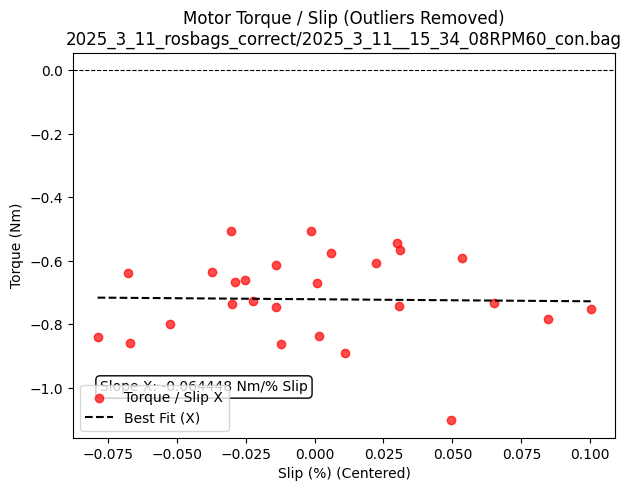

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.stats import linregress


# def mad_based_filter(data, threshold=3.5):
#     median = np.nanmedian(data)
#     mad = np.nanmedian(np.abs(data - median)) + 1e-6
#     modified_z_score = 0.6745 * (data - median) / mad
#     return np.abs(modified_z_score) < threshold


# def remove_2d_outliers(x_data, y_data, threshold=1.5):
#     valid_mask = ~np.isnan(x_data) & ~np.isnan(y_data)

#     if valid_mask.sum() < 2:
#         return x_data, y_data

#     x_valid, y_valid = x_data[valid_mask], y_data[valid_mask]

#     # Separate filtering
#     mask_x = mad_based_filter(x_valid, threshold)
#     mask_y = mad_based_filter(y_valid, threshold)

#     combined_mask = mask_x & mask_y

#     x_out = np.full_like(x_data, np.nan)
#     y_out = np.full_like(y_data, np.nan)

#     valid_indices = np.where(valid_mask)[0]
#     x_out[valid_indices[combined_mask]] = x_valid[combined_mask]
#     y_out[valid_indices[combined_mask]] = y_valid[combined_mask]

#     return x_out, y_out


# def plot_torque_vs_slip_xy(t_vec, slip_x, slip_y, avg_currents, vicon_velocity,
#                            velocity_threshold, bag_filename, start=None, stop=None):

#     if start is not None:
#         slip_x, slip_y = slip_x[start:], slip_y[start:]
#         vicon_velocity, avg_currents_data = vicon_velocity[start:], avg_currents.data[:, start:]
#     else:
#         avg_currents_data = avg_currents.data

#     if stop is not None and stop > 0:
#         slip_x, slip_y = slip_x[:-stop], slip_y[:-stop]
#         vicon_velocity, avg_currents_data = vicon_velocity[:-stop], avg_currents_data[:, :-stop]

#     velocity_mask = vicon_velocity > velocity_threshold
#     slip_x, slip_y = np.where(velocity_mask, slip_x, np.nan), np.where(velocity_mask, slip_y, np.nan)

#     motor_torque = -avg_currents_data

#     slip_x_safe = np.where(np.abs(slip_x) > 1e-6, slip_x, np.nan)
#     torque_x = motor_torque[0] / slip_x_safe

#     slip_x_filtered, torque_x_filtered = remove_2d_outliers(slip_x_safe, torque_x, threshold=3.5)

#     slip_x_standardized = slip_x_filtered - np.nanmean(slip_x_filtered)

#     valid_mask_x = ~np.isnan(slip_x_standardized) & ~np.isnan(torque_x_filtered)
#     slip_x_valid, torque_x_valid = slip_x_standardized[valid_mask_x], torque_x_filtered[valid_mask_x]

#     if len(slip_x_valid) < 2:
#         print("Insufficient valid points after filtering.")
#         return

#     slope_x, intercept_x, _, _, _ = linregress(slip_x_valid, torque_x_valid)
#     print(f"Longitudinal Stiffness (Slope X): {slope_x:.6f} Nm/% Slip")

#     slip_x_fit = np.linspace(np.nanmin(slip_x_standardized), np.nanmax(slip_x_standardized), 100)
#     torque_x_fit = slope_x * slip_x_fit + intercept_x

#     fig, ax = plt.subplots(figsize=(7, 5), dpi=100)
#     ax.scatter(slip_x_standardized, torque_x_filtered, color="red", alpha=0.7, label="Torque / Slip X")
#     ax.plot(slip_x_fit, torque_x_fit, color="black", linestyle="--", label="Best Fit (X)")

#     ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
#     ax.set_xlabel("Slip (%) (Centered)")
#     ax.set_ylabel("Torque (Nm)")
#     ax.set_title(f"Motor Torque / Slip (Outliers Removed)\n{bag_filename}")

#     ax.legend()
#     ax.text(0.05, 0.15, f"Slope X: {slope_x:.6f} Nm/% Slip", transform=ax.transAxes, fontsize=10,
#             verticalalignment='top', bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white"))

#     safe_filename = bag_filename.replace("/", "_").replace("\\", "_")
#     plt.savefig(f"torque_vs_slip_{safe_filename}.png", dpi=300, bbox_inches='tight')
#     print(f"Plot saved as torque_vs_slip_{safe_filename}.png")

#     plt.show()



# # vicon_velocity = bags[0].vicon_vels.x

# # print(slip_x)
# # Example usage:
# plot_torque_vs_slip_xy(
#     t_vec, 
#     slip_x, 
#     slip_y, 
#     avg_currents, 
#     vicon_velocity=Vx_vicon_resampled, 
#     velocity_threshold=0.01,  # Change this threshold as needed
#     bag_filename=str(bag_filename), 
# )
